# Modelo de estimacion de caudal (QMD) — Palma Central
### Random Forest vs XGBoost | Version simplificada y muy comentada

**Objetivo:** estimar el caudal diario (QMD) en la estacion TARGET a partir de
variables de caudal, nivel y precipitacion de estaciones vecinas, usando dos
modelos (Random Forest y XGBoost), y generar la prediccion fuera de muestra
para el periodo 2011-2025.

**Sobre las funciones:** este notebook usa funciones (bloques de codigo con
nombre, que se escriben una vez y se "llaman" cuantas veces se necesiten).
Cada funcion tiene un comentario explicando que recibe, que hace y que
devuelve — no hace falta saber programar para seguir el hilo, solo lee los
comentarios en orden.

**Reglas metodologicas que sigue este notebook (no negociables en series de tiempo):**
1. El split TRAIN/TEST es **cronologico** (80% mas antiguo / 20% mas reciente).
   Nunca se mezcla al azar: el futuro no debe usarse para predecir el pasado.
2. El tuning de hiperparametros usa **TimeSeriesSplit con gap**, no K-Fold comun,
   para no inflar el desempeno por autocorrelacion.
3. RF y XGB seleccionan sus variables **cada uno con su propia importancia**
   (no se reutiliza la seleccion de uno para el otro), porque aunque ambos
   son modelos de arbol, RF (bagging) y XGB (boosting) pueden valorar las
   variables distinto.
4. Se reporta siempre el **GAP** (R2 train - R2 test) como diagnostico de
   sobreajuste, igual para ambos modelos, para poder compararlos.

**Estructura:**
- Celda 1: Carga y unificacion de datos
- Celda 1b: Mapa de datos faltantes (fijo e interactivo)
- Celda 2: Ingenieria de variables (LAG1) + split cronologico
- Celda 3: Funciones comunes (metricas, graficos, imputacion)
- Celda 4: Random Forest (tuning, entrenamiento, evaluacion train/test)
- Celda 5: XGBoost (tuning, entrenamiento, evaluacion train/test)
- Celda 6: Diagnostico de sobreajuste + pruebas estadisticas (defensa)
- Celda 7: Prediccion fuera de muestra 2011-2025 (ambos modelos)
- Celda 8: Resumen final de metricas (tabla de cierre)
- Celda 9: Visualizacion interactiva de RF y XGB (train, test y prediccion)
- Celda 10: Animaciones GIF (ajuste segun numero de arboles y ventanas walk-forward)


## Celda 1 — Carga y unificacion de datos

In [2]:
# ============================================================
# CELDA 1 — CARGA Y UNIFICACION DE DATOS
# ============================================================
from google.colab import files
import pandas as pd
import numpy as np
import io

print("Selecciona los CSV de entrenamiento:")
uploaded = files.upload()


# ------------------------------------------------------------
# FUNCION 1: leer_csv
# ------------------------------------------------------------
# Una funcion es un bloque de codigo con nombre. En vez de copiar y
# pegar estas ~15 lineas 9 veces (una por archivo), se escriben UNA
# vez aqui y se "llaman" (se usan) 9 veces mas abajo.
# - Lo que va entre parentesis, def leer_csv(contenido), es lo que la
#   funcion NECESITA para trabajar (aqui: el archivo en bytes).
# - Lo que sigue a "return" es lo que la funcion ENTREGA de vuelta
#   (aqui: un DataFrame ya limpio, con columnas 'Fecha' y 'Valor').
def leer_csv(contenido):
    """
    Recibe el contenido de un CSV (en bytes) y devuelve un DataFrame
    limpio con columnas 'Fecha' y 'Valor'. Prueba varias combinaciones
    de encoding/separador porque no todos los CSV se guardan igual
    (Excel en espanol suele usar ';' y encoding 'latin1'; otros usan
    ',' y 'utf-8').
    """
    df = None
    for enc in ["utf-8", "utf-8-sig", "latin1", "cp1252"]:
        for sep in [None, ",", ";", "\t"]:
            try:
                tmp = pd.read_csv(io.BytesIO(contenido), encoding=enc, sep=sep, engine="python")
                if tmp.shape[1] >= 2:
                    df = tmp.copy()
                    break
            except Exception:
                pass
        if df is not None:
            break
    if df is None:
        raise ValueError("No se pudo leer uno de los archivos.")

    df.columns = [str(c).strip() for c in df.columns]
    col_fecha = next((c for c in df.columns if "fecha" in c.lower() or "date" in c.lower()), df.columns[0])
    col_valor = next((c for c in df.columns if any(k in c.lower() for k in ["valor", "caudal", "nivel", "flow"])), df.columns[1])
    df = df[[col_fecha, col_valor]].rename(columns={col_fecha: "Fecha", col_valor: "Valor"})

    s = df["Fecha"].astype(str).str.strip().str.replace("\ufeff", "", regex=False).str.replace("T", " ", regex=False)
    f_mes_primero = pd.to_datetime(s, errors="coerce", dayfirst=False)
    f_dia_primero = pd.to_datetime(s, errors="coerce", dayfirst=True)
    df["Fecha"] = f_dia_primero if f_dia_primero.isna().sum() < f_mes_primero.isna().sum() else f_mes_primero

    df["Valor"] = pd.to_numeric(df["Valor"], errors="coerce")
    df = df.dropna().copy()
    df["Fecha"] = df["Fecha"].dt.normalize()
    return df.groupby("Fecha", as_index=False)["Valor"].mean()


# ------------------------------------------------------------
# FUNCION 2: asignar_alias
# ------------------------------------------------------------
# Recibe el NOMBRE del archivo (ej. "COTOCA_QMD_2007.csv") y devuelve
# el nombre estandar de la variable ("COTOCA_QMD"). Si en el futuro
# cambian los nombres de tus archivos, SOLO tocas esta funcion.
def asignar_alias(nombre_archivo):
    """Mapea el nombre de archivo a una variable estandar."""
    n = nombre_archivo.upper()
    if "TARGET" in n:                        return "TARGET"
    if "CHIMA" in n:                         return "CHIMA_PRECIP"
    if "MOMIL" in n:                         return "MOMIL_PRECIP"
    if "DOCTRINA" in n:                      return "DOCTRINA_PRECIP"
    if "PALMACENTRAL" in n and "NIVEL" in n: return "PALMA_NIV"
    if "COTOCA" in n and "QMD" in n:         return "COTOCA_QMD"
    if "COTOCA" in n and "NIVEL" in n:       return "COTOCA_NIV"
    if "SABANA" in n and "QMD" in n:         return "SABANA_QMD"
    if "SABANA" in n and "NIVEL" in n:       return "SABANA_NIV"
    return nombre_archivo


# ------------------------------------------------------------
# USO DE LAS FUNCIONES: aqui es donde realmente se ejecutan
# ------------------------------------------------------------
dfs_alias = {}
for nombre, contenido in uploaded.items():
    alias = asignar_alias(nombre.replace(".csv", ""))
    df_i  = leer_csv(contenido)
    df_i  = df_i.rename(columns={"Valor": alias})
    dfs_alias[alias] = df_i
    print(f"  '{nombre}' -> '{alias}'  ({len(df_i)} filas)")

if "TARGET" not in dfs_alias:
    raise ValueError("No se encontro la columna TARGET entre los archivos subidos.")

# Union de todas las series por fecha (outer join = conserva TODAS las
# fechas de TODOS los archivos, aunque a alguno le falten dias).
df_merge = None
for alias, df_i in dfs_alias.items():
    df_merge = df_i if df_merge is None else df_merge.merge(df_i, on="Fecha", how="outer")
df_merge = df_merge.sort_values("Fecha").reset_index(drop=True)

print(f"\ndf_merge: {df_merge.shape[0]} filas x {df_merge.shape[1]} columnas")
print(f"Rango de fechas: {df_merge['Fecha'].min().date()} -> {df_merge['Fecha'].max().date()}")
print("% de datos faltantes por columna:")
print((df_merge.drop(columns='Fecha').isna().mean() * 100).round(1).to_string())


Selecciona los CSV de entrenamiento:


Saving 1.CHIMA_PRECIP_13075010_1991_2010_CSV.csv to 1.CHIMA_PRECIP_13075010_1991_2010_CSV.csv
Saving 2.MOMIL_PRECIP_1991_2010_CSV_13070020.csv to 2.MOMIL_PRECIP_1991_2010_CSV_13070020.csv
Saving 3. PALMACENTRAL_NIVELES_1991_2010_CSV.csv to 3. PALMACENTRAL_NIVELES_1991_2010_CSV.csv
Saving 4. COTOCA ABAJO QMD19912010 CSV.csv to 4. COTOCA ABAJO QMD19912010 CSV.csv
Saving 5. COTOCA ABAJO NIVELES 1991 2010  CSV.csv to 5. COTOCA ABAJO NIVELES 1991 2010  CSV.csv
Saving 6. LA DOCTRINA PRECIPITACION 1991 2010.csv to 6. LA DOCTRINA PRECIPITACION 1991 2010.csv
Saving 7. QMD SABANANUEVA 1991 2010 CSV.csv to 7. QMD SABANANUEVA 1991 2010 CSV.csv
Saving 8. SABANANUEVA NIVELES 1991 2010 CSV.csv to 8. SABANANUEVA NIVELES 1991 2010 CSV.csv
Saving 9. QMD TARGET PALMA CENTRAL 1991 2010 CSV.csv to 9. QMD TARGET PALMA CENTRAL 1991 2010 CSV.csv
  '1.CHIMA_PRECIP_13075010_1991_2010_CSV.csv' -> 'CHIMA_PRECIP'  (6777 filas)
  '2.MOMIL_PRECIP_1991_2010_CSV_13070020.csv' -> 'MOMIL_PRECIP'  (6996 filas)
  '3. PALM

## Celda 1b — Mapa de datos faltantes

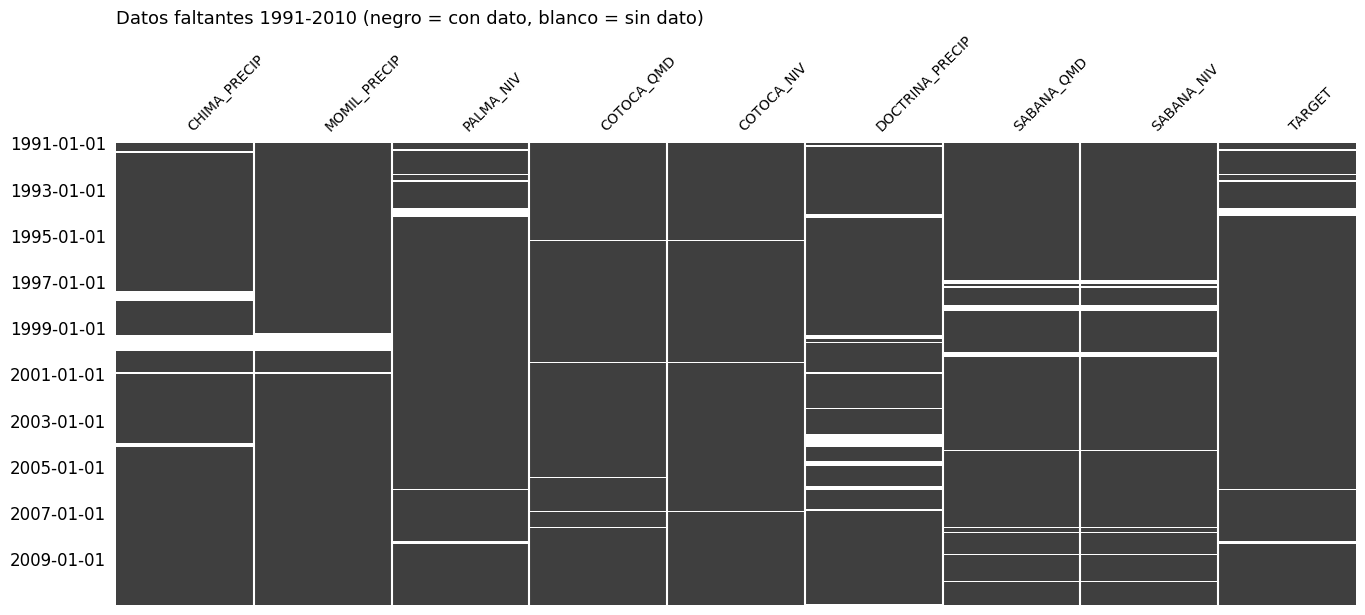

Días totales: 7305
Días completos con precipitación   : 5619 (76.9 %)
Días completos sin precipitación   : 6631 (90.8 %)
(Estos conteos no incluyen el efecto de las variables LAG1, que quitan algunos días más.)


In [3]:
# ============================================================
# CELDA 1b — MAPA DE DATOS FALTANTES (1991-2010)
# Muestra, día por día y variable por variable, dónde hay dato y dónde no.
# Dos versiones: missingno (imagen fija para la tesis) y plotly (interactiva:
# zoom con el mouse y, al pasar el cursor, la fecha y la variable).
# ============================================================
import sys, subprocess
try:
    import missingno as msno
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "missingno"], check=True)
    import missingno as msno
import plotly.graph_objects as go
import matplotlib.pyplot as plt

try:
    df_merge
except NameError:
    raise NameError("Ejecuta la Celda 1 primero.")

# Serie diaria completa: cada fecha del periodo aparece una vez, tenga o no datos
df_mapa = (df_merge.set_index("Fecha")
           .reindex(pd.date_range(df_merge["Fecha"].min(), df_merge["Fecha"].max(), freq="D")))
df_mapa.index.name = "Fecha"

# --- 1) Versión fija (missingno): barra negra = hay dato, blanco = falta ---
ax = msno.matrix(df_mapa, freq="2YS", figsize=(16, 6), fontsize=10, sparkline=False)
ax.set_title("Datos faltantes 1991-2010 (negro = con dato, blanco = sin dato)", fontsize=13, loc="left")
plt.savefig("mapa_faltantes_1991_2010.png", dpi=200, bbox_inches="tight")
plt.show()

# --- 2) Versión interactiva (plotly) ---
def mapa_faltantes_interactivo(df, titulo):
    """Recibe un DataFrame con índice de fechas y dibuja un mapa interactivo:
    azul = con dato, gris claro = sin dato. Devuelve la figura."""
    presencia = df.notna().astype(int).T
    texto = [["con dato" if v else "SIN DATO" for v in fila] for fila in presencia.values]
    fig = go.Figure(go.Heatmap(
        z=presencia.values, x=df.index, y=presencia.index,
        zmin=0, zmax=1, colorscale=[[0, "#e4e3df"], [1, "#2a78d6"]], showscale=False,
        customdata=texto,
        hovertemplate="%{y}<br>%{x|%Y-%m-%d}: %{customdata}<extra></extra>"))
    pct = (df.isna().mean() * 100).round(1)
    fig.update_yaxes(ticktext=[f"{c} ({pct[c]} % faltante)" for c in presencia.index],
                     tickvals=list(presencia.index), autorange="reversed")
    fig.update_layout(title=titulo, height=120 + 45 * len(presencia), template="plotly_white",
                      xaxis=dict(rangeslider=dict(visible=True), type="date"),
                      margin=dict(l=10, r=10, t=60, b=10))
    fig.show()
    return fig

fig_faltantes = mapa_faltantes_interactivo(df_mapa, "Datos faltantes 1991-2010 — azul = con dato, gris = sin dato")
fig_faltantes.write_html("mapa_faltantes_1991_2010.html")

# Cuántos días deja el filtro de filas completas, con y sin las 3 de precipitación
precip = ["CHIMA_PRECIP", "MOMIL_PRECIP", "DOCTRINA_PRECIP"]
vars_modelo = [c for c in df_mapa.columns if c != "PALMA_NIV"]
n_con  = df_mapa[vars_modelo].dropna().shape[0]
n_sin  = df_mapa[[c for c in vars_modelo if c not in precip]].dropna().shape[0]
print(f"Días totales: {len(df_mapa)}")
print(f"Días completos con precipitación   : {n_con} ({n_con/len(df_mapa)*100:.1f} %)")
print(f"Días completos sin precipitación   : {n_sin} ({n_sin/len(df_mapa)*100:.1f} %)")
print("(Estos conteos no incluyen el efecto de las variables LAG1, que quitan algunos días más.)")


## Celda 2 — Ingenieria de variables (LAG1) y split cronologico

In [4]:
# ============================================================
# CELDA 2 — INGENIERIA DE VARIABLES (LAG1) + SPLIT CRONOLOGICO
# Esta celda no necesita funciones nuevas: son pasos que se hacen
# una sola vez, en orden, sobre el df_merge de la Celda 1.
# ============================================================
try:
    df_merge
except NameError:
    raise NameError("Ejecuta la Celda 1 primero.")

df_lag = df_merge.copy()

# LAG1 = el valor del dia ANTERIOR. Se agrega solo para caudal y nivel
# (tienen autocorrelacion fuerte dia a dia: el caudal de hoy se parece
# mucho al de ayer). La precipitacion NO se rezaga: su efecto sobre el
# caudal es del mismo dia, no del dia siguiente.
for col in ["COTOCA_QMD", "SABANA_QMD", "COTOCA_NIV", "SABANA_NIV"]:
    if col in df_lag.columns:
        df_lag[f"{col}_LAG1"] = df_lag[col].shift(1)

TARGET_COL = "TARGET"

# PALMA_NIV se EXCLUYE de las candidatas: es la misma estacion del
# TARGET, asi que usarla como predictora seria fuga de informacion
# (el modelo "haria trampa" viendo casi la respuesta).
CANDIDATAS = [
    "COTOCA_QMD", "COTOCA_QMD_LAG1", "SABANA_QMD", "SABANA_QMD_LAG1",
    "COTOCA_NIV", "COTOCA_NIV_LAG1", "SABANA_NIV", "SABANA_NIV_LAG1",
    "CHIMA_PRECIP", "MOMIL_PRECIP", "DOCTRINA_PRECIP",
]
PREDICTORES = [c for c in CANDIDATAS if c in df_lag.columns]

print("Correlacion de cada candidata con TARGET (ordenada, de mayor a menor):")
print(df_lag[[TARGET_COL] + PREDICTORES].corr()[TARGET_COL].drop(TARGET_COL)
      .sort_values(ascending=False).round(3).to_string())

# Dataset final: "listwise" significa que se descartan las filas que
# tengan CUALQUIER dato faltante (el modelo no puede entrenar con huecos).
df_ml = (df_lag[[TARGET_COL] + PREDICTORES + ["Fecha"]]
         .dropna().sort_values("Fecha").reset_index(drop=True))

# --- SPLIT CRONOLOGICO 80/20 ---
# El 80% de fechas mas antiguas entrena, el 20% mas reciente evalua.
# Esto es obligatorio en series de tiempo: nunca usar un split aleatorio
# aqui, porque mezclaria fechas del futuro dentro del entrenamiento
# (el modelo "veria" indirectamente lo que se supone debe predecir).
CORTE = int(len(df_ml) * 0.8)
train, test = df_ml.iloc[:CORTE], df_ml.iloc[CORTE:]
X_train, y_train = train[PREDICTORES], train[TARGET_COL]
X_test,  y_test  = test[PREDICTORES],  test[TARGET_COL]

print(f"\nDataset final: {len(df_ml)} filas ({len(PREDICTORES)} predictoras)")
print(f"TRAIN: {len(train)} filas | {train['Fecha'].min().date()} -> {train['Fecha'].max().date()}")
print(f"TEST : {len(test)} filas | {test['Fecha'].min().date()} -> {test['Fecha'].max().date()}")


Correlacion de cada candidata con TARGET (ordenada, de mayor a menor):
COTOCA_NIV         0.976
COTOCA_QMD         0.975
COTOCA_NIV_LAG1    0.956
COTOCA_QMD_LAG1    0.955
SABANA_QMD         0.915
SABANA_NIV         0.907
SABANA_QMD_LAG1    0.899
SABANA_NIV_LAG1    0.889
DOCTRINA_PRECIP    0.169
MOMIL_PRECIP       0.143
CHIMA_PRECIP       0.132

Dataset final: 5541 filas (11 predictoras)
TRAIN: 4432 filas | 1991-01-02 -> 2007-08-08
TEST : 1109 filas | 2007-08-09 -> 2010-12-17


## Celda 3 — Funciones comunes (metricas, graficos, imputacion)\n\nSe definen **una sola vez** aqui y las usan tanto RF como XGB en las celdas 4 y 5 — asi no se repite el mismo codigo dos veces. Cada funcion tiene un comentario explicando que recibe y que devuelve.

In [5]:
# ============================================================
# CELDA 3 — FUNCIONES COMUNES
# ============================================================
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
from sklearn.model_selection import learning_curve


# ------------------------------------------------------------
# FUNCION: nse (Nash-Sutcliffe Efficiency)
# ------------------------------------------------------------
# Recibe: obs (valores reales) y pred (valores predichos).
# Devuelve: un numero. 1 = prediccion perfecta, 0 = tan bueno como usar
# siempre el promedio, negativo = peor que usar el promedio.
# Es el indicador estandar en hidrologia (mas usado ahi que el R2 solo).
def nse(obs, pred):
    obs, pred = np.asarray(obs), np.asarray(pred)
    return 1 - np.sum((obs - pred) ** 2) / np.sum((obs - obs.mean()) ** 2)


# ------------------------------------------------------------
# FUNCION: pbias (sesgo porcentual)
# ------------------------------------------------------------
# Devuelve un porcentaje: positivo = el modelo SOBREESTIMA el caudal,
# negativo = el modelo SUBESTIMA el caudal.
def pbias(obs, pred):
    obs, pred = np.asarray(obs), np.asarray(pred)
    return 100 * np.sum(pred - obs) / np.sum(obs)




# ------------------------------------------------------------
# FUNCION: kge (Kling-Gupta Efficiency)
# ------------------------------------------------------------
def kge(obs, pred):
    obs, pred = np.asarray(obs), np.asarray(pred)
    r = np.corrcoef(obs, pred)[0, 1]
    alpha = np.std(pred) / np.std(obs)
    beta = np.mean(pred) / np.mean(obs)
    return 1 - np.sqrt((r - 1) ** 2 + (alpha - 1) ** 2 + (beta - 1) ** 2)


# ------------------------------------------------------------
# FUNCION: ioa (Index of Agreement de Willmott)
# ------------------------------------------------------------
def ioa(obs, pred):
    obs, pred = np.asarray(obs), np.asarray(pred)
    num = np.sum((obs - pred) ** 2)
    den = np.sum((np.abs(pred - obs.mean()) + np.abs(obs - obs.mean())) ** 2)
    return 1 - num / den



# ------------------------------------------------------------
# FUNCION: calcular_metricas
# ------------------------------------------------------------
# Recibe: obs, pred, y una etiqueta de texto (ej. "TRAIN" o "TEST").
# Calcula 7 metricas de una vez y las imprime en una sola linea.
# Devuelve: un diccionario {"R2": ..., "NSE": ..., ...} para poder
# despues armar tablas comparativas con esos numeros.
def calcular_metricas(obs, pred, etiqueta, imprimir=True):
    m = {
        # R2 = cuadrado del coeficiente de correlacion de Pearson (r2), como se usa
        # en hidrologia (Moriasi et al., 2007). Se cambio porque r2_score de sklearn
        # usa la misma formula que NSE y repetia el mismo numero.
        "R2":    np.corrcoef(obs, pred)[0, 1] ** 2,
        "NSE":   nse(obs, pred),
        "RMSE":  np.sqrt(mean_squared_error(obs, pred)),
        "MAE":   mean_absolute_error(obs, pred),
        "PBIAS": pbias(obs, pred),
        "KGE":   kge(obs, pred),
        "IOA":   ioa(obs, pred)
    }
    if imprimir:
        print(f"{etiqueta}: R2={m['R2']:.4f} | NSE={m['NSE']:.4f} | "
              f"RMSE={m['RMSE']:.2f} | MAE={m['MAE']:.2f} | PBIAS={m['PBIAS']:.2f}% | "
              f"KGE={m['KGE']:.4f} | IOA={m['IOA']:.4f}")
    return m


# ------------------------------------------------------------
# FUNCION: graficar_train_test
# ------------------------------------------------------------
# Recibe: las fechas y valores observados/predichos de TRAIN y de TEST,
# el nombre del modelo (para el titulo) y un color.
# Dibuja UNA figura con 2 paneles (arriba TRAIN, abajo TEST), cada uno
# con sus propias metricas en el titulo.
# Devuelve: las metricas de TRAIN y de TEST (para usarlas despues, ej.
# en la tabla resumen de la Celda 8).
def graficar_train_test(fechas_train, obs_train, pred_train,
                         fechas_test, obs_test, pred_test,
                         nombre_modelo, color):
    m_tr = calcular_metricas(obs_train, pred_train, "TRAIN", imprimir=False)
    m_te = calcular_metricas(obs_test,  pred_test,  "TEST",  imprimir=False)

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 9), sharey=True)

    ax1.plot(fechas_train, obs_train,  "k", lw=1.0, label="Observado")
    ax1.plot(fechas_train, pred_train, color=color, lw=1.0, label=f"{nombre_modelo} predicho")
    ax1.set_title(f"{nombre_modelo} — TRAIN | R2={m_tr['R2']:.3f} | RMSE={m_tr['RMSE']:.1f} | MAE={m_tr['MAE']:.1f} m3/s")
    ax1.legend(); ax1.grid(alpha=0.3)

    ax2.plot(fechas_test, obs_test,  "k", lw=1.2, label="Observado")
    ax2.plot(fechas_test, pred_test, color=color, lw=1.2, label=f"{nombre_modelo} predicho")
    ax2.fill_between(fechas_test, obs_test, pred_test, color=color, alpha=0.15, label="Error")
    ax2.set_title(f"{nombre_modelo} — TEST | R2={m_te['R2']:.3f} | RMSE={m_te['RMSE']:.1f} | MAE={m_te['MAE']:.1f} m3/s")
    ax2.set_xlabel("Fecha"); ax2.legend(); ax2.grid(alpha=0.3)
    for ax in (ax1, ax2):
        ax.set_ylabel("QMD (m3/s)"); ax.tick_params(axis="x", rotation=45)
    plt.tight_layout(); plt.show()
    return m_tr, m_te


# ------------------------------------------------------------
# FUNCION: seleccionar_variables_por_importancia
# ------------------------------------------------------------
# Recibe: un modelo YA entrenado, la lista de todas las variables
# candidatas, y un umbral (ej. 0.98 = 98%).
# Ordena las variables de mas a menos importante segun el modelo, y se
# queda solo con las necesarias para acumular ese % de importancia
# total (asi se descartan las que casi no aportan nada).
# Devuelve: la lista de variables seleccionadas + la tabla completa de
# importancias (para poder mostrarla).
def seleccionar_variables_por_importancia(modelo, predictoras, umbral=0.98, minimo=3):
    imp = (pd.DataFrame({"Variable": predictoras, "Importancia": modelo.feature_importances_})
           .sort_values("Importancia", ascending=False).reset_index(drop=True))
    imp["Importancia_norm"] = imp["Importancia"] / imp["Importancia"].sum()
    imp["Acumulada"] = imp["Importancia_norm"].cumsum()
    n = max(int(np.searchsorted(imp["Acumulada"].values, umbral)) + 1, minimo)
    seleccionadas = imp["Variable"].head(n).tolist()
    print(imp.to_string(index=False))
    print(f"-> {n} variable(s) seleccionadas (umbral {umbral*100:.0f}%): {seleccionadas}")
    return seleccionadas, imp


# ------------------------------------------------------------
# FUNCION: validar_con_permutation_importance
# ------------------------------------------------------------
# OJO: a diferencia de la funcion anterior (que mide importancia en
# TRAIN), esta la mide en TEST (datos que el modelo NUNCA vio entrenando).
# Funciona "revolviendo" al azar los valores de una variable y viendo
# cuanto EMPEORA el modelo sin esa informacion util. Si una variable
# resulta con importancia ~0 aqui, es señal de que la seleccion hecha
# en TRAIN puede estar algo sobreajustada a ese conjunto.
def validar_con_permutation_importance(modelo, X_test, y_test, variables):
    perm = permutation_importance(modelo, X_test[variables], y_test,
                                   n_repeats=30, random_state=42, scoring="r2", n_jobs=-1)
    df_perm = (pd.DataFrame({"Variable": variables,
                              "Importancia_perm_TEST": perm.importances_mean,
                              "Desv_std": perm.importances_std})
               .sort_values("Importancia_perm_TEST", ascending=False).reset_index(drop=True))
    print(df_perm.to_string(index=False))
    return df_perm


# ------------------------------------------------------------
# FUNCION: graficar_curva_aprendizaje
# ------------------------------------------------------------
# Entrena el modelo varias veces, cada vez con MAS datos de TRAIN
# (20%, 36%, 52%... hasta 100%), y mide el R2 en cada caso.
# Si la linea de "entrenamiento" y la de "validacion" quedan muy
# separadas y no se acercan al agregar mas datos, es señal de
# sobreajuste que no se arregla con mas datos (hay que simplificar
# el modelo o las variables, no conseguir mas informacion).
def graficar_curva_aprendizaje(modelo, X, y, nombre_modelo, cv):
    tam, score_train, score_val = learning_curve(
        modelo, X, y, cv=cv, scoring="r2", n_jobs=-1,
        train_sizes=np.linspace(0.2, 1.0, 6))
    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(tam, score_train.mean(axis=1), "o-", label="R2 entrenamiento")
    ax.plot(tam, score_val.mean(axis=1), "o--", label="R2 validacion (CV)")
    ax.set_title(f"Curva de aprendizaje — {nombre_modelo}")
    ax.set_xlabel("N observaciones de entrenamiento"); ax.set_ylabel("R2")
    ax.legend(); ax.grid(alpha=0.3); plt.tight_layout(); plt.show()


# ------------------------------------------------------------
# FUNCION: imputar
# ------------------------------------------------------------
# Recibe una columna con huecos (NaN) y los rellena: spline cubico
# (una curva suave) para huecos cortos (<= `limite` dias), y lineal
# (una recta) para el resto. Se usa SOLO al construir el set de
# prediccion 2011-2025 (Celda 7) — nunca sobre TRAIN/TEST del modelado,
# porque ahi ya se trabajo solo con filas completas.
def imputar(serie, limite=7):
    serie = serie.copy()
    s_spline = serie.interpolate(method="spline", order=3, limit=limite, limit_direction="both")
    s_lineal = serie.interpolate(method="linear", limit_direction="both")
    serie[serie.isna()] = s_spline[serie.isna()].fillna(s_lineal[serie.isna()])
    return serie


print("Funciones listas: nse, pbias, kge, ioa, calcular_metricas, graficar_train_test, "
      "seleccionar_variables_por_importancia, validar_con_permutation_importance, "
      "graficar_curva_aprendizaje, imputar.")


Funciones listas: nse, pbias, kge, ioa, calcular_metricas, graficar_train_test, seleccionar_variables_por_importancia, validar_con_permutation_importance, graficar_curva_aprendizaje, imputar.


## Celda 4 — Random Forest: tuning, entrenamiento y evaluacion

=== INICIANDO VALIDACIÓN WALK-FORWARD DE RANDOM FOREST ===

🔄 EJECUTANDO VENTANA TEMPORAL RF 1 DE 3
Mejores hiperparámetros detectados en Ventana 1: {'n_estimators': 300, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10, 'bootstrap': True}
       Variable  Importancia  Importancia_norm  Acumulada
     COTOCA_NIV     0.251780          0.251780   0.251780
     COTOCA_QMD     0.245742          0.245742   0.497522
COTOCA_NIV_LAG1     0.128375          0.128375   0.625897
COTOCA_QMD_LAG1     0.114193          0.114193   0.740090
     SABANA_QMD     0.096643          0.096643   0.836733
     SABANA_NIV     0.068396          0.068396   0.905130
SABANA_QMD_LAG1     0.049631          0.049631   0.954761
SABANA_NIV_LAG1     0.043931          0.043931   0.998692
DOCTRINA_PRECIP     0.000903          0.000903   0.999595
   CHIMA_PRECIP     0.000294          0.000294   0.999889
   MOMIL_PRECIP     0.000111          0.000111   1.000000
-> 8 variable(s) seleccion

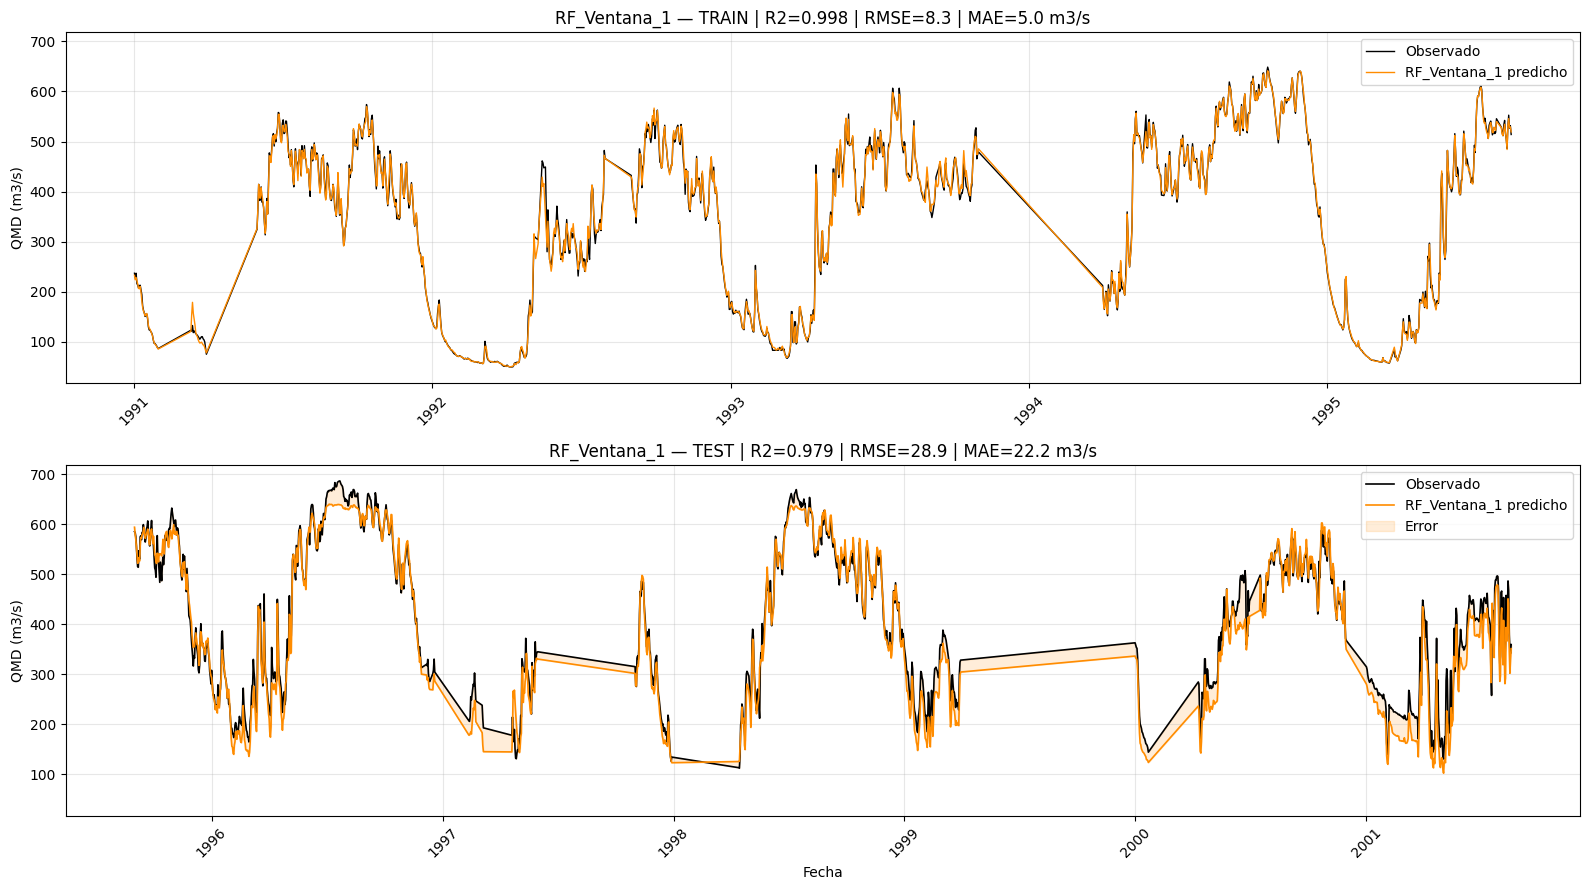

📈 [VISUAL] Curva de Aprendizaje Temporal - Ventana Temporal 1:


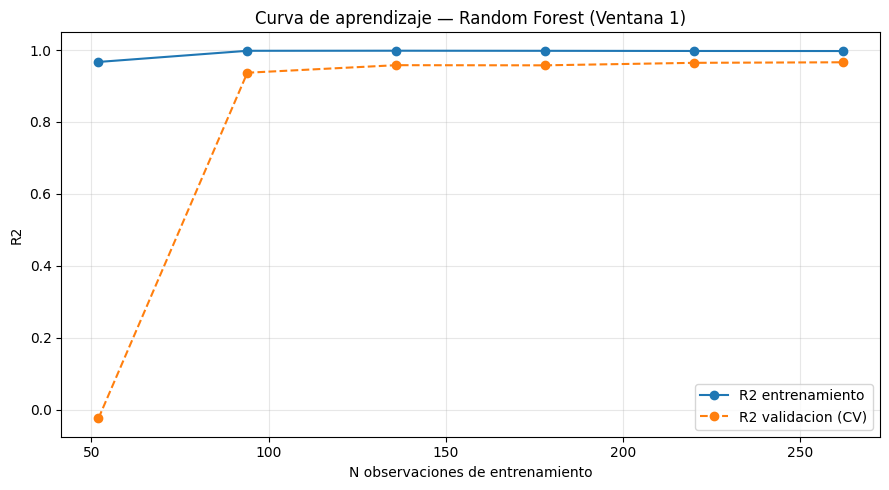


🔄 EJECUTANDO VENTANA TEMPORAL RF 2 DE 3
Mejores hiperparámetros detectados en Ventana 2: {'n_estimators': 300, 'min_samples_split': 4, 'min_samples_leaf': 2, 'max_features': 'log2', 'max_depth': 10, 'bootstrap': True}
       Variable  Importancia  Importancia_norm  Acumulada
     COTOCA_NIV     0.274876          0.274876   0.274876
     COTOCA_QMD     0.199494          0.199494   0.474369
COTOCA_NIV_LAG1     0.155603          0.155603   0.629972
     SABANA_QMD     0.107989          0.107989   0.737962
COTOCA_QMD_LAG1     0.092409          0.092409   0.830370
     SABANA_NIV     0.074680          0.074680   0.905050
SABANA_NIV_LAG1     0.050062          0.050062   0.955112
SABANA_QMD_LAG1     0.043774          0.043774   0.998885
DOCTRINA_PRECIP     0.000693          0.000693   0.999578
   CHIMA_PRECIP     0.000252          0.000252   0.999830
   MOMIL_PRECIP     0.000170          0.000170   1.000000
-> 8 variable(s) seleccionadas (umbral 98%): ['COTOCA_NIV', 'COTOCA_QMD', 'COTOCA_NIV

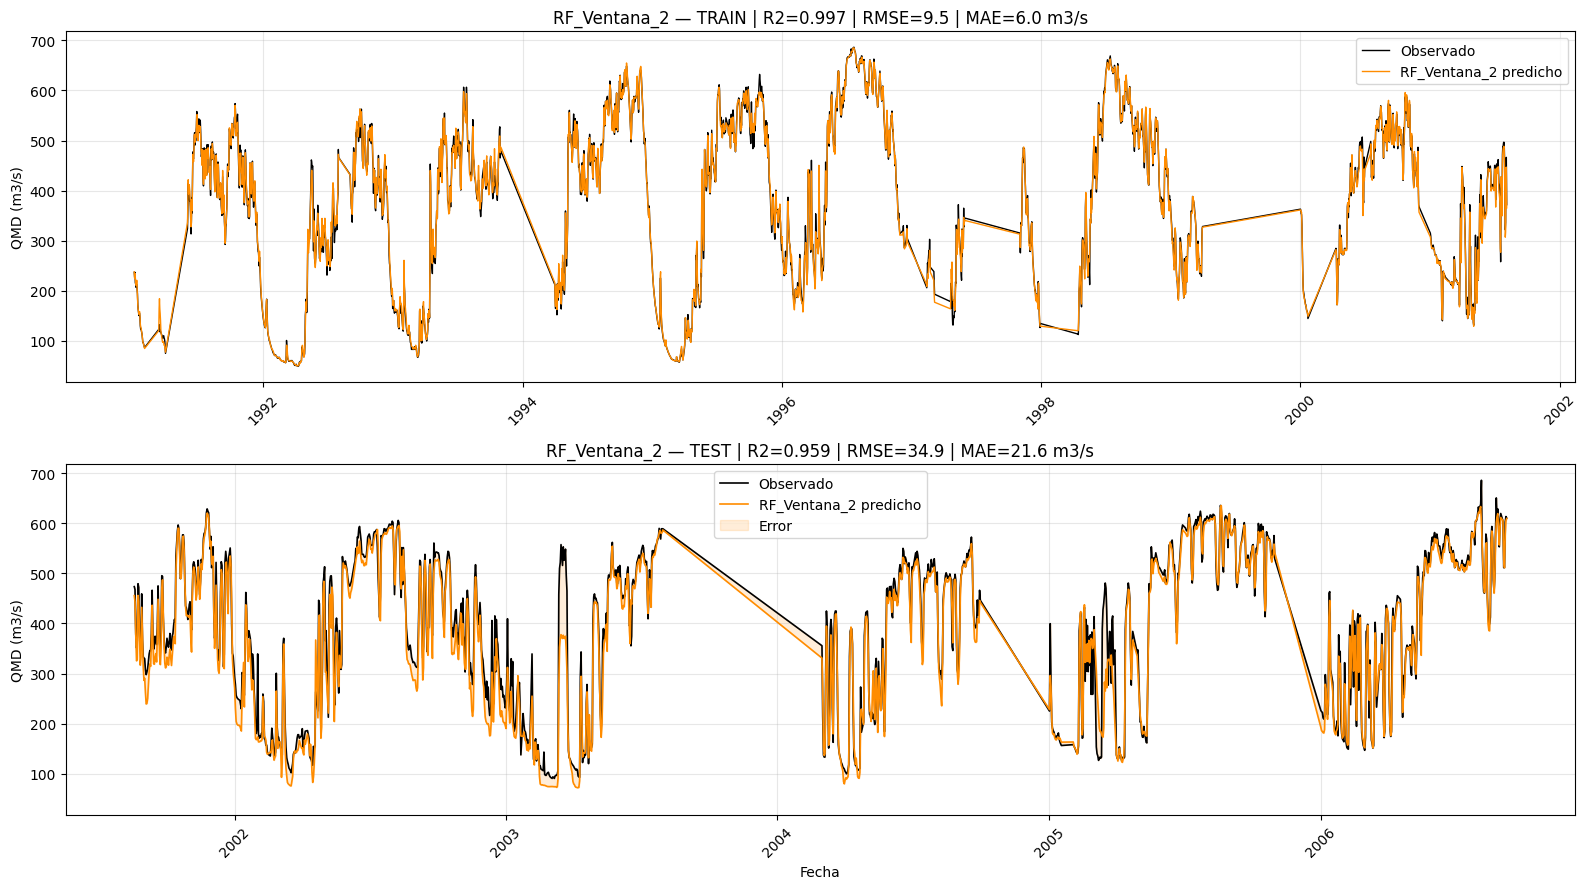

📈 [VISUAL] Curva de Aprendizaje Temporal - Ventana Temporal 2:


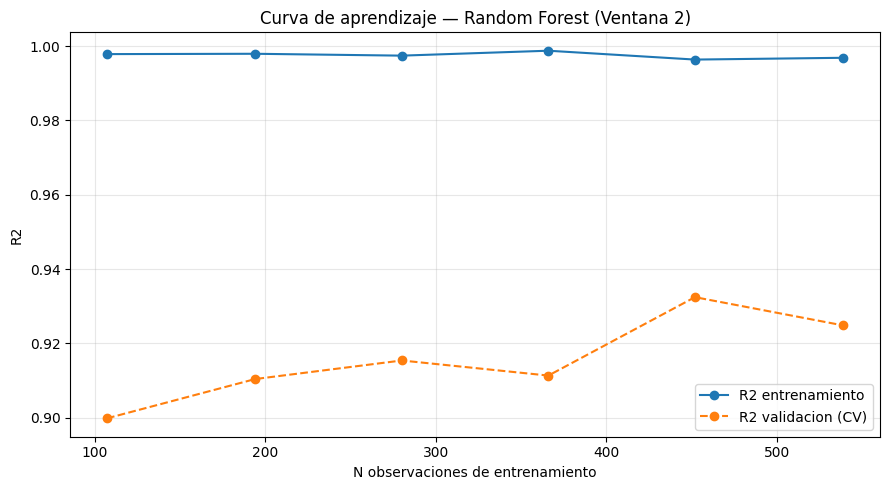


🔄 EJECUTANDO VENTANA TEMPORAL RF 3 DE 3
Mejores hiperparámetros detectados en Ventana 3: {'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 5, 'max_features': 0.5, 'max_depth': None, 'bootstrap': True}
       Variable  Importancia  Importancia_norm  Acumulada
     COTOCA_NIV     0.461141          0.461141   0.461141
     COTOCA_QMD     0.284061          0.284061   0.745201
COTOCA_NIV_LAG1     0.114043          0.114043   0.859244
COTOCA_QMD_LAG1     0.062858          0.062858   0.922102
     SABANA_QMD     0.053051          0.053051   0.975153
     SABANA_NIV     0.015183          0.015183   0.990336
SABANA_QMD_LAG1     0.006484          0.006484   0.996820
SABANA_NIV_LAG1     0.002900          0.002900   0.999719
DOCTRINA_PRECIP     0.000124          0.000124   0.999844
   CHIMA_PRECIP     0.000096          0.000096   0.999940
   MOMIL_PRECIP     0.000060          0.000060   1.000000
-> 6 variable(s) seleccionadas (umbral 98%): ['COTOCA_NIV', 'COTOCA_QMD', 'COTOCA_NIV_

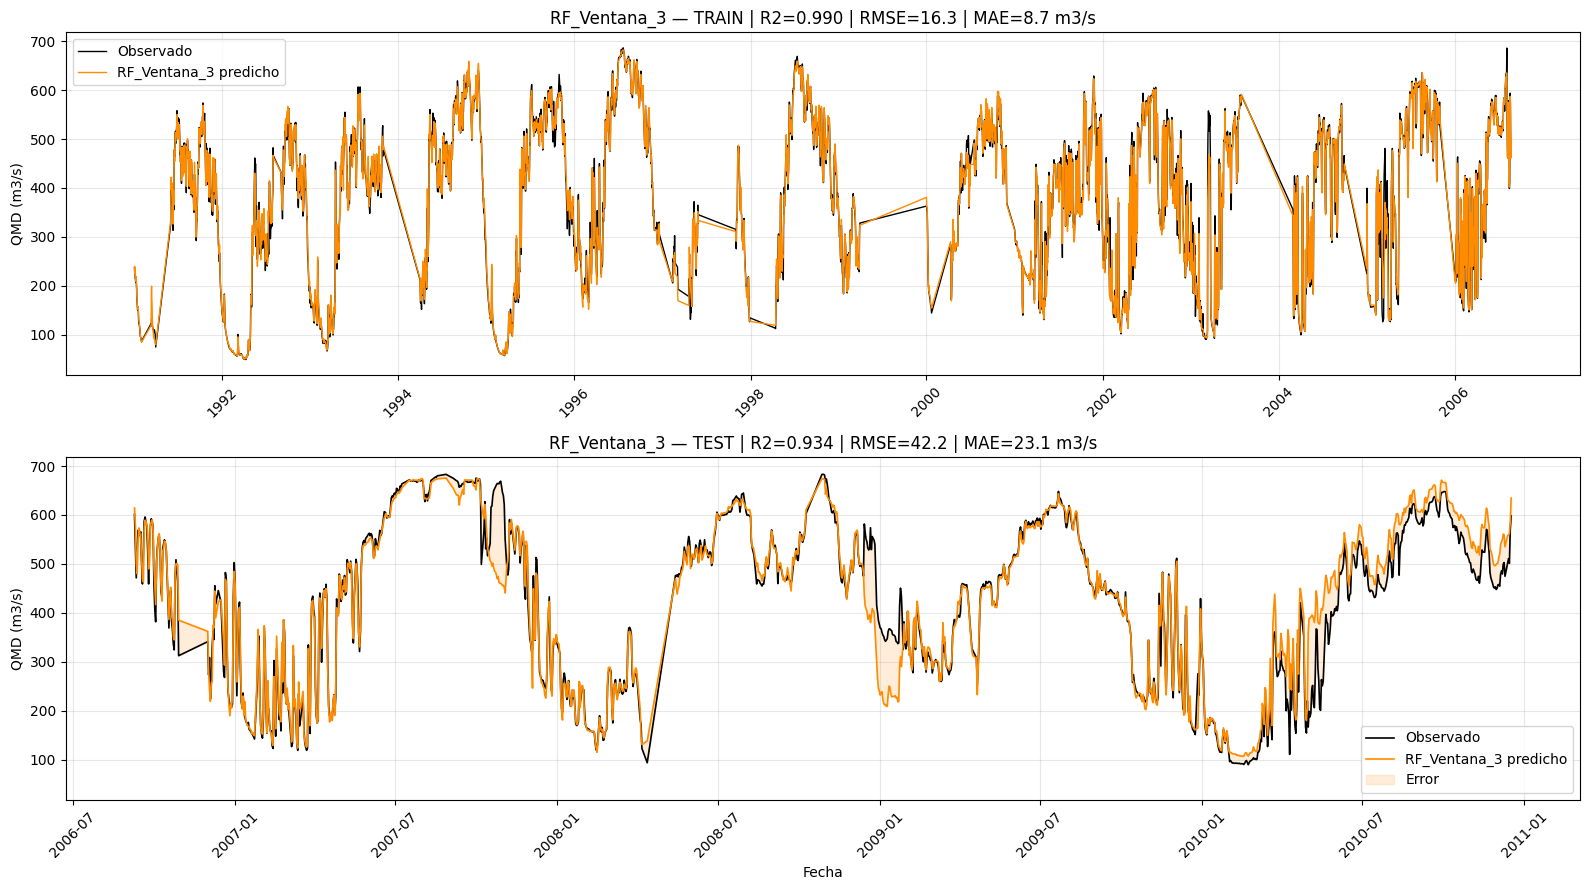

📈 [VISUAL] Curva de Aprendizaje Temporal - Ventana Temporal 3:


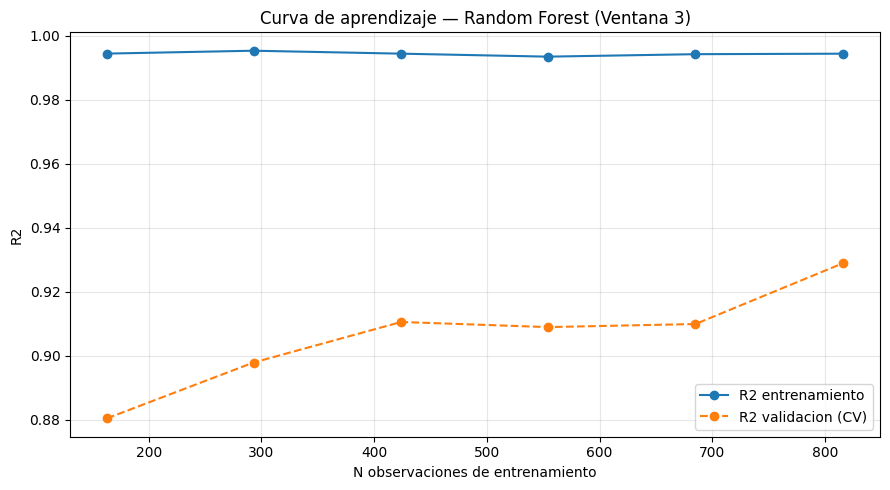


🏁 VALIDACIÓN WALK-FORWARD DE RF FINALIZADA CON ÉXITO

📊 RESUMEN RANDOM FOREST DETALLADO POR VENTANA TEMPORAL:

➔ Ventana 1:
  TRAIN ➔ R2: 0.998 | NSE: 0.998 | RMSE: 8.298 | MAE: 4.996 | PBIAS: -0.031 | KGE: 0.996 | IOA: 0.999
  TEST  ➔ R2: 0.979 | NSE: 0.961 | RMSE: 28.943 | MAE: 22.225 | PBIAS: -3.710 | KGE: 0.920 | IOA: 0.991

➔ Ventana 2:
  TRAIN ➔ R2: 0.997 | NSE: 0.997 | RMSE: 9.494 | MAE: 5.965 | PBIAS: -0.013 | KGE: 0.995 | IOA: 0.999
  TEST  ➔ R2: 0.959 | NSE: 0.949 | RMSE: 34.866 | MAE: 21.631 | PBIAS: -3.795 | KGE: 0.956 | IOA: 0.987

➔ Ventana 3:
  TRAIN ➔ R2: 0.990 | NSE: 0.990 | RMSE: 16.265 | MAE: 8.735 | PBIAS: -0.000 | KGE: 0.990 | IOA: 0.997
  TEST  ➔ R2: 0.934 | NSE: 0.932 | RMSE: 42.245 | MAE: 23.097 | PBIAS: 1.085 | KGE: 0.964 | IOA: 0.983

🏆 RENDIMIENTO PROMEDIO GLOBAL RF (PARA COPIAR EN TESIS)
📊 Métrica RF: R2
   TRAIN Promedio : 0.9947 (± 0.0035)
   TEST  Promedio : 0.9572 (± 0.0183)
   GAP Promedio (TRAIN - TEST): 0.0375
----------------------------------------

In [6]:
# ============================================================
# NUEVA CELDA 4 — RANDOM FOREST (OPTIMIZADA, REPRODUCIBLE Y VISUAL)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

try:
    df_ml
except NameError:
    raise NameError("Por favor, ejecuta primero las Celdas 1 y 2 para cargar los datos.")

# 1. Definimos las 3 ventanas temporales de evaluación final
n_ventanas_test = 3
tscv_test = TimeSeriesSplit(n_splits=n_ventanas_test, gap=14)  # gap agregado: evita fuga por autocorrelacion LAG1 entre train y test

X_completo = df_ml[PREDICTORES]
y_completo = df_ml[TARGET_COL]

# Listas para almacenar los diccionarios de métricas de cada ventana
lista_metricas_train = []
lista_metricas_test = []
lista_mejores_parametros = []
# Se guardan las predicciones de TEST del modelo FINAL de cada ventana (con las
# variables seleccionadas) para que la Celda 6 evalúe exactamente estos modelos.
lista_pred_test_rf = []
lista_pred_train_rf = []
lista_modelos_rf = []
lista_vars_rf = []
lista_obs_train_rf = []
lista_fechas_train_rf = []
lista_obs_test_rf = []
lista_fechas_test_rf = []
vuelta = 1

print("=== INICIANDO VALIDACIÓN WALK-FORWARD DE RANDOM FOREST ===")

for train_index, test_index in tscv_test.split(X_completo):
    print(f"\n" + "="*50)
    print(f"🔄 EJECUTANDO VENTANA TEMPORAL RF {vuelta} DE {n_ventanas_test}")
    print(f"="*50)

    # Separación cronológica dinámica
    X_tr, X_te = X_completo.iloc[train_index], X_completo.iloc[test_index]
    y_tr, y_te = y_completo.iloc[train_index], y_completo.iloc[test_index]
    df_tr, df_te = df_ml.iloc[train_index], df_ml.iloc[test_index]

    # Validación cruzada INTERNA (para buscar parámetros dentro de este TRAIN)
    tscv_interno = TimeSeriesSplit(n_splits=4, gap=14)

    # Grilla de hiperparámetros restaurada
    grid_rf = {
        "n_estimators": [100, 200, 300, 500, 700],
        "max_depth": [5, 10, 15, None],
        "min_samples_leaf": [2, 4, 5, 6, 7, 8],
        "min_samples_split": [2, 4, 5, 6, 7, 8],
        "max_features": ["sqrt", "log2", 0.3, 0.5, 0.8, None],
        "bootstrap": [True, False]
    }

    # CORRECCIÓN DE ALEATORIEDAD: random_state=42 congela los resultados finales (siempre idénticos)
    rs_rf = RandomizedSearchCV(
        estimator=RandomForestRegressor(random_state=42, n_jobs=-1),
        param_distributions=grid_rf,
        n_iter=60,
        cv=tscv_interno,
        scoring="r2",
        n_jobs=-1,
        verbose=0,
        random_state=42
    )

    rs_rf.fit(X_tr, y_tr)
    lista_mejores_parametros.append(rs_rf.best_params_)
    print(f"Mejores hiperparámetros detectados en Ventana {vuelta}: {rs_rf.best_params_}")

    # --- Selección de variables e Importancia ---
    rf_completo = RandomForestRegressor(**rs_rf.best_params_, random_state=42, n_jobs=-1)
    rf_completo.fit(X_tr, y_tr)
    VARS_RF, imp_rf = seleccionar_variables_por_importancia(rf_completo, PREDICTORES, umbral=0.98)

    # --- Modelo FINAL de la ventana ---
    rf_final = RandomForestRegressor(**rs_rf.best_params_, random_state=42, n_jobs=-1)
    rf_final.fit(X_tr[VARS_RF], y_tr)

    pred_train_rf = rf_final.predict(X_tr[VARS_RF])
    pred_test_rf  = rf_final.predict(X_te[VARS_RF])
    lista_pred_test_rf.append(pred_test_rf)
    lista_pred_train_rf.append(pred_train_rf)
    lista_modelos_rf.append(rf_final)
    lista_vars_rf.append(VARS_RF)
    lista_obs_train_rf.append(y_tr.values)
    lista_fechas_train_rf.append(df_tr["Fecha"].values)
    lista_obs_test_rf.append(y_te.values)
    lista_fechas_test_rf.append(df_te["Fecha"].values)

    # --- CORRECCIÓN DE GRÁFICOS: Despliegue inmediato en pantalla sin plt.close() ---
    print(f"\n📈 [VISUAL] Predicción Hidrológica - Ventana Temporal {vuelta}:")
    metricas_train_rf, metricas_test_rf = graficar_train_test(
        df_tr["Fecha"], y_tr, pred_train_rf,
        df_te["Fecha"], y_te, pred_test_rf,
        nombre_modelo=f"RF_Ventana_{vuelta}", color="darkorange")
    plt.show()

    print(f"📈 [VISUAL] Curva de Aprendizaje Temporal - Ventana Temporal {vuelta}:")
    graficar_curva_aprendizaje(
        RandomForestRegressor(**rs_rf.best_params_, random_state=42, n_jobs=-1),
        X_tr[VARS_RF], y_tr, f"Random Forest (Ventana {vuelta})", cv=tscv_interno
    )
    plt.show()

    # Guardamos las métricas extraídas para los consolidados finales
    lista_metricas_train.append(metricas_train_rf)
    lista_metricas_test.append(metricas_test_rf)

    vuelta += 1

print("\n" + "="*60)
print("🏁 VALIDACIÓN WALK-FORWARD DE RF FINALIZADA CON ÉXITO")
print("="*60)


# ============================================================
# EXTRACCIÓN Y REPORTE GLOBAL EN FORMATO HORIZONTAL
# ============================================================
# Lista completa de indicadores hidrológicos requeridos
metricas_interes = ["R2", "NSE", "RMSE", "MAE", "PBIAS", "KGE", "IOA"]

print("\n📊 RESUMEN RANDOM FOREST DETALLADO POR VENTANA TEMPORAL:")
for i in range(n_ventanas_test):
    print(f"\n➔ Ventana {i+1}:")
    # Formateo horizontal limpio para lectura rápida
    str_train = "  TRAIN ➔ "
    str_test  = "  TEST  ➔ "
    for m in metricas_interes:
        str_train += f"{m}: {lista_metricas_train[i][m]:.3f} | "
        str_test  += f"{m}: {lista_metricas_test[i][m]:.3f} | "
    print(str_train[:-3])
    print(str_test[:-3])

print("\n" + "="*60)
print("🏆 RENDIMIENTO PROMEDIO GLOBAL RF (PARA COPIAR EN TESIS)")
print("="*60)

for m in metricas_interes:
    vals_tr = [dic[m] for dic in lista_metricas_train]
    vals_te = [dic[m] for dic in lista_metricas_test]

    # Despliegue unificado por métrica
    print(f"📊 Métrica RF: {m}")
    print(f"   TRAIN Promedio : {np.mean(vals_tr):.4f} (± {np.std(vals_tr):.4f})")
    print(f"   TEST  Promedio : {np.mean(vals_te):.4f} (± {np.std(vals_te):.4f})")
    if m in ["R2", "NSE", "KGE", "IOA"]:
        print(f"   GAP Promedio (TRAIN - TEST): {np.mean(vals_tr) - np.mean(vals_te):.4f}")
    print("-" * 40)

## Celda 5 — XGBoost: tuning, entrenamiento y evaluacion

=== INICIANDO VALIDACIÓN WALK-FORWARD DE XGBOOST ===

🚀 EJECUTANDO VENTANA TEMPORAL XGBOOST 1 DE 3
Mejores hiperparámetros detectados en XGB Ventana 1: {'subsample': 1.0, 'n_estimators': 300, 'min_child_weight': 5, 'max_depth': 10, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
       Variable  Importancia  Importancia_norm  Acumulada
     COTOCA_NIV     0.543744          0.543744   0.543744
     COTOCA_QMD     0.314319          0.314319   0.858063
COTOCA_QMD_LAG1     0.054957          0.054957   0.913020
COTOCA_NIV_LAG1     0.051227          0.051227   0.964247
     SABANA_NIV     0.019118          0.019118   0.983365
     SABANA_QMD     0.010444          0.010444   0.993809
SABANA_QMD_LAG1     0.002875          0.002875   0.996684
SABANA_NIV_LAG1     0.002045          0.002045   0.998729
DOCTRINA_PRECIP     0.000560          0.000560   0.999289
   CHIMA_PRECIP     0.000409          0.000409   0.999698
   MOMIL_PRECIP     0.000302          0.000302   1.000000
-> 5 variable(s) selecci

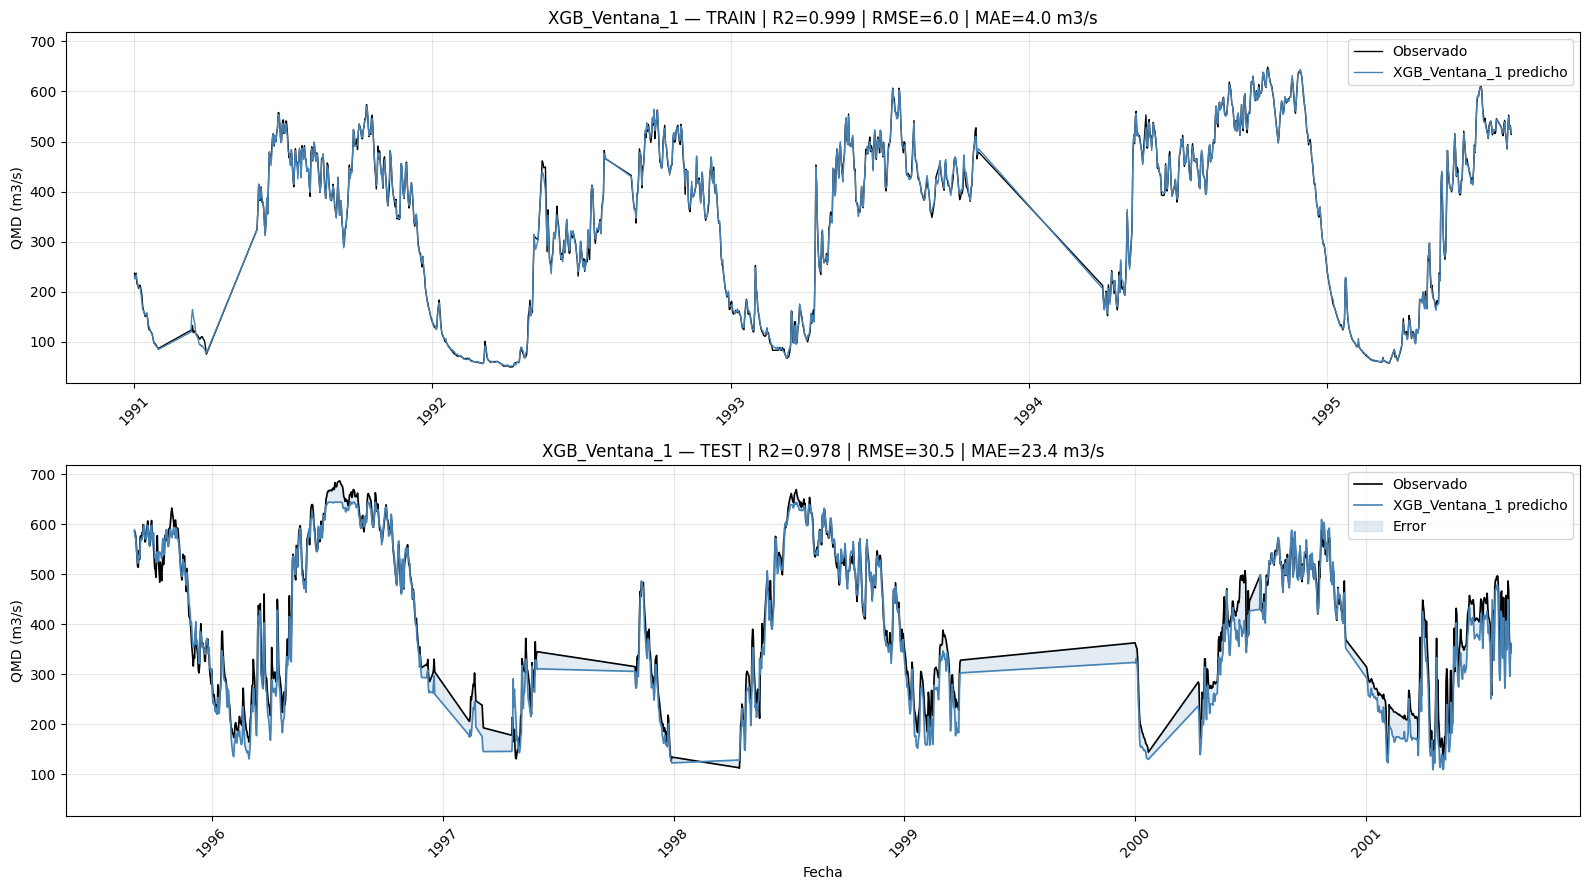

📈 [VISUAL] Curva de Aprendizaje Temporal XGB - Ventana Temporal 1:


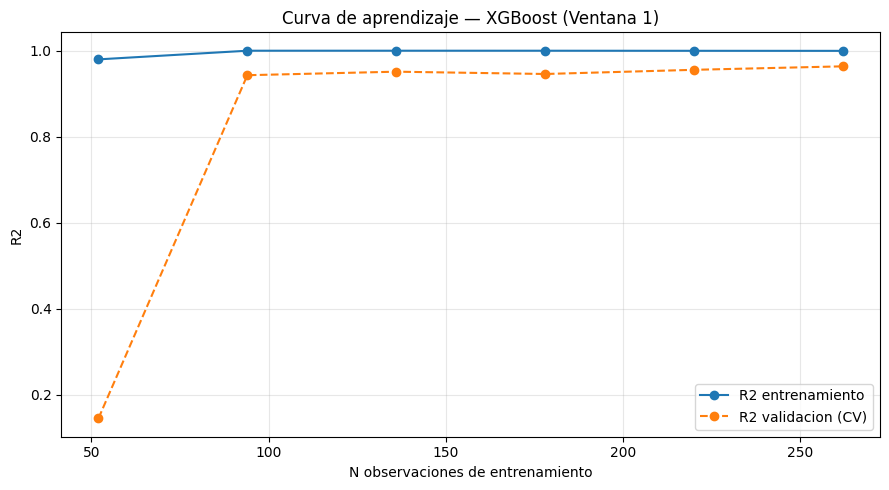


🚀 EJECUTANDO VENTANA TEMPORAL XGBOOST 2 DE 3
Mejores hiperparámetros detectados en XGB Ventana 2: {'subsample': 1.0, 'n_estimators': 500, 'min_child_weight': 4, 'max_depth': 15, 'learning_rate': 0.01, 'colsample_bytree': 0.8}
       Variable  Importancia  Importancia_norm  Acumulada
     COTOCA_NIV     0.745796          0.745796   0.745796
COTOCA_NIV_LAG1     0.143405          0.143405   0.889200
     COTOCA_QMD     0.057586          0.057586   0.946786
     SABANA_QMD     0.022108          0.022108   0.968894
COTOCA_QMD_LAG1     0.014141          0.014141   0.983035
     SABANA_NIV     0.008018          0.008018   0.991053
SABANA_QMD_LAG1     0.006100          0.006100   0.997153
SABANA_NIV_LAG1     0.001239          0.001239   0.998391
DOCTRINA_PRECIP     0.000562          0.000562   0.998954
   CHIMA_PRECIP     0.000536          0.000536   0.999489
   MOMIL_PRECIP     0.000511          0.000511   1.000000
-> 5 variable(s) seleccionadas (umbral 98%): ['COTOCA_NIV', 'COTOCA_NIV_LAG1'

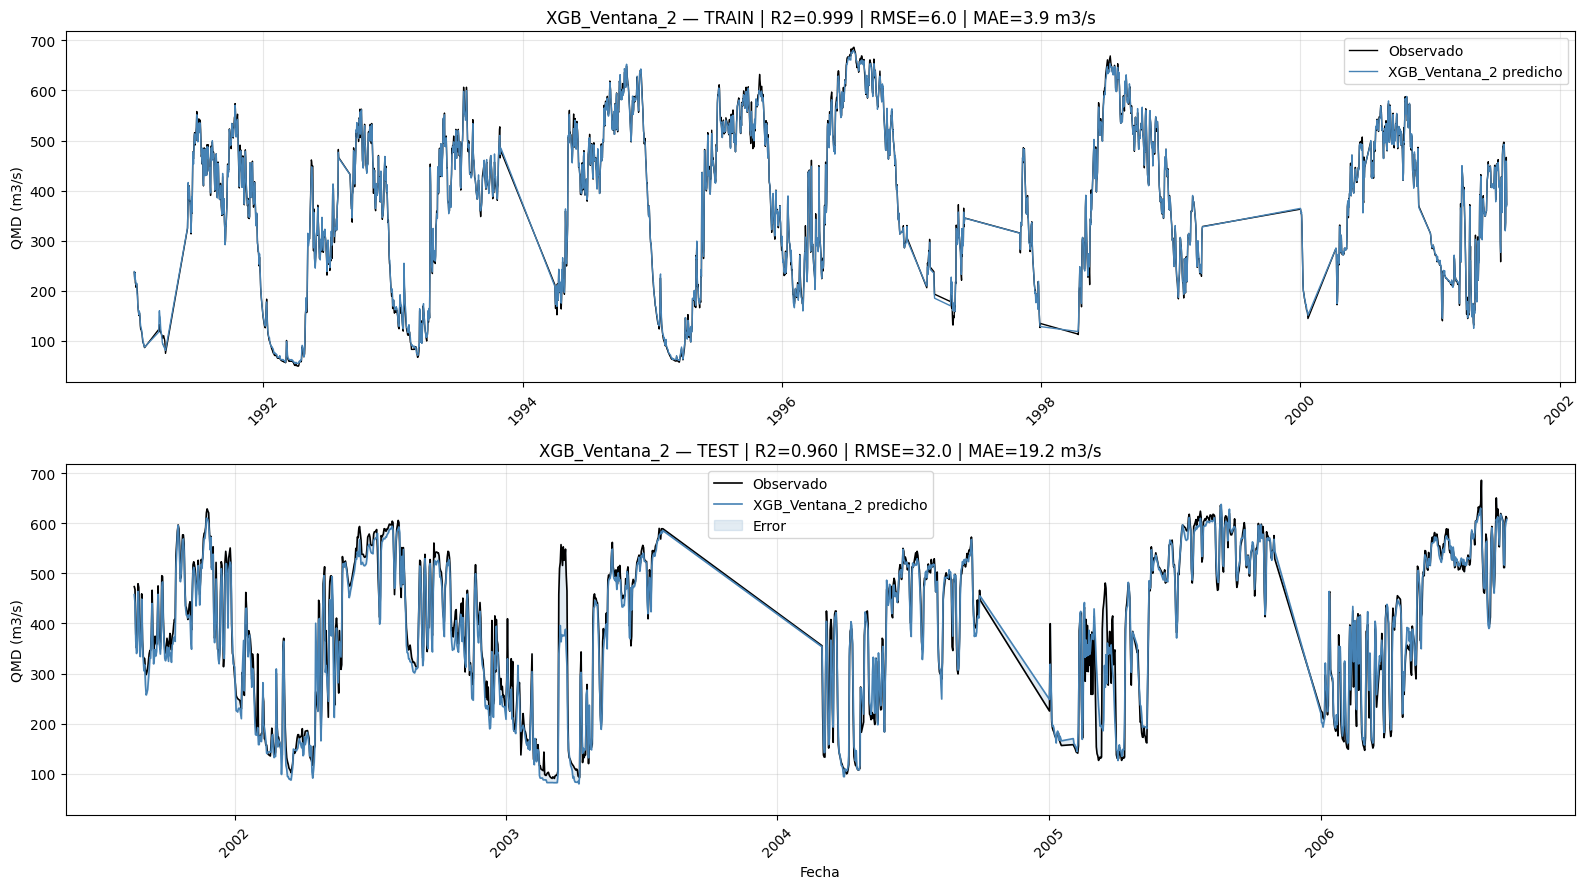

📈 [VISUAL] Curva de Aprendizaje Temporal XGB - Ventana Temporal 2:


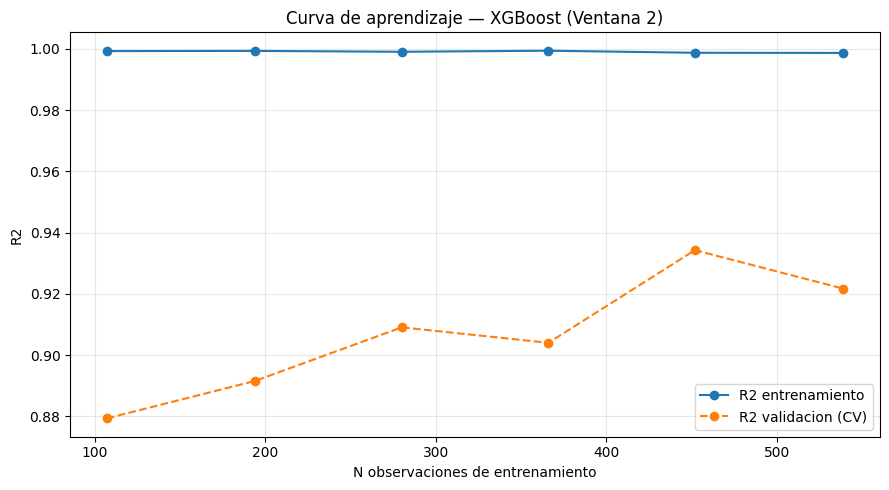


🚀 EJECUTANDO VENTANA TEMPORAL XGBOOST 3 DE 3
Mejores hiperparámetros detectados en XGB Ventana 3: {'subsample': 1.0, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 15, 'learning_rate': 0.05, 'colsample_bytree': 0.7}
       Variable  Importancia  Importancia_norm  Acumulada
     COTOCA_NIV     0.770963          0.770963   0.770963
     COTOCA_QMD     0.104533          0.104533   0.875496
COTOCA_QMD_LAG1     0.063257          0.063257   0.938753
COTOCA_NIV_LAG1     0.024542          0.024542   0.963295
     SABANA_QMD     0.020158          0.020158   0.983453
     SABANA_NIV     0.007777          0.007777   0.991230
SABANA_QMD_LAG1     0.003353          0.003353   0.994583
SABANA_NIV_LAG1     0.003109          0.003109   0.997692
DOCTRINA_PRECIP     0.000816          0.000816   0.998508
   CHIMA_PRECIP     0.000790          0.000790   0.999298
   MOMIL_PRECIP     0.000703          0.000703   1.000000
-> 5 variable(s) seleccionadas (umbral 98%): ['COTOCA_NIV', 'COTOCA_QMD', 'CO

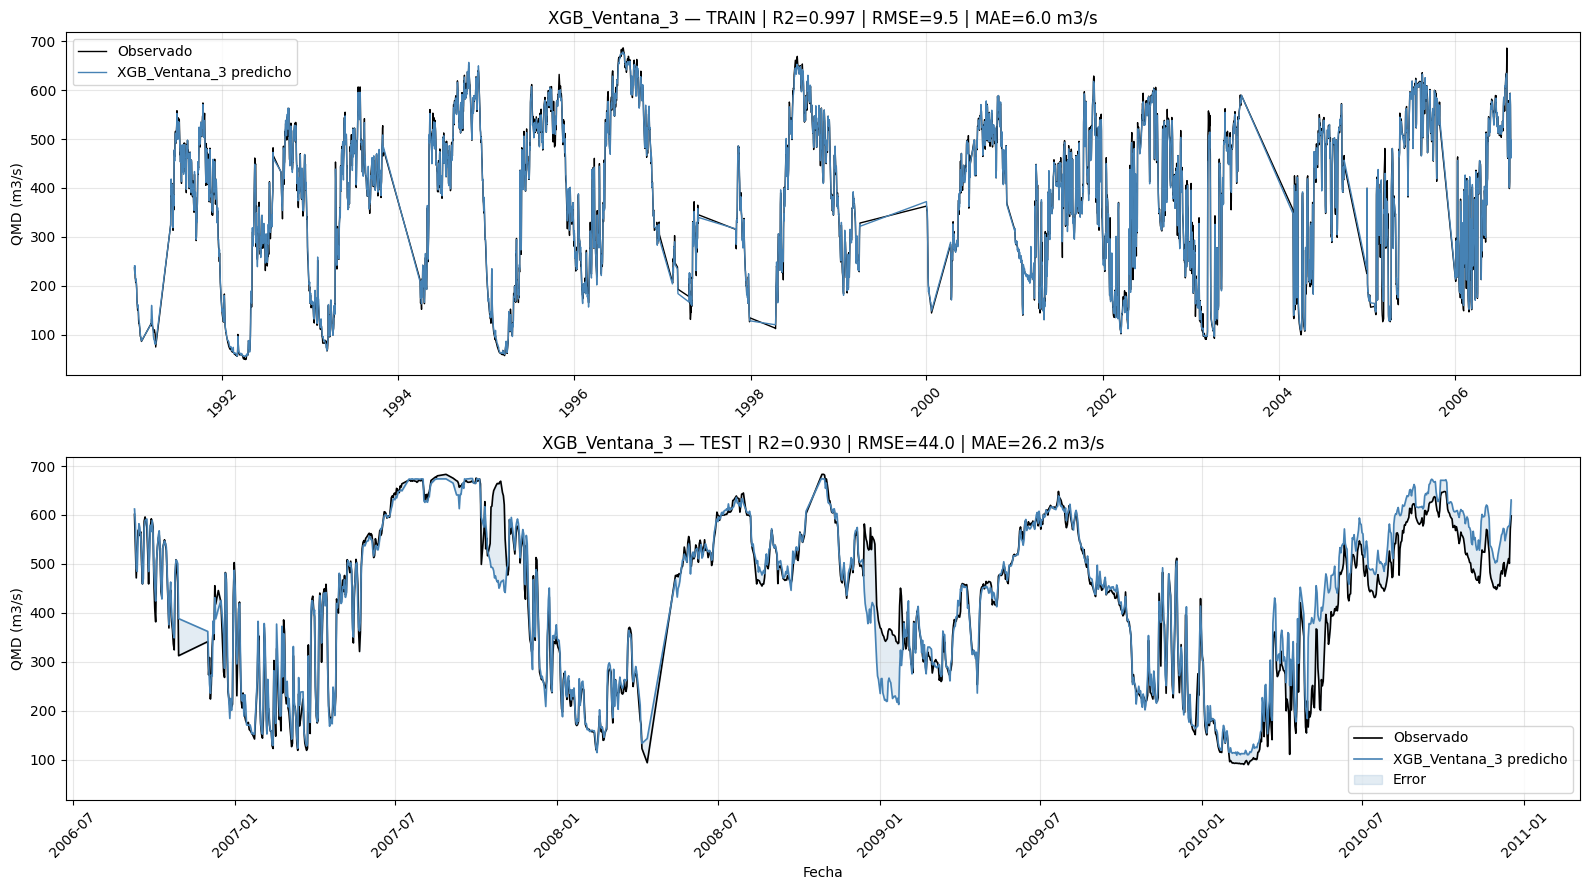

📈 [VISUAL] Curva de Aprendizaje Temporal XGB - Ventana Temporal 3:


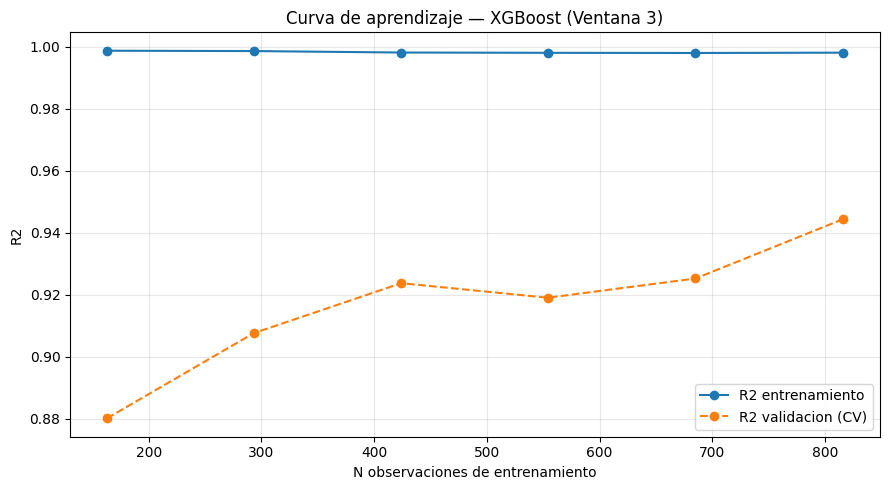


🏁 VALIDACIÓN WALK-FORWARD DE XGBOOST FINALIZADA CON ÉXITO

📊 RESUMEN XGBOOST DETALLADO POR VENTANA TEMPORAL:

➔ Ventana 1:
  TRAIN ➔ R2: 0.999 | NSE: 0.999 | RMSE: 5.952 | MAE: 3.959 | PBIAS: -0.001 | KGE: 0.998 | IOA: 1.000
  TEST  ➔ R2: 0.978 | NSE: 0.957 | RMSE: 30.528 | MAE: 23.433 | PBIAS: -4.337 | KGE: 0.918 | IOA: 0.990

➔ Ventana 2:
  TRAIN ➔ R2: 0.999 | NSE: 0.999 | RMSE: 5.995 | MAE: 3.949 | PBIAS: -0.007 | KGE: 0.989 | IOA: 1.000
  TEST  ➔ R2: 0.960 | NSE: 0.957 | RMSE: 31.965 | MAE: 19.188 | PBIAS: -1.915 | KGE: 0.966 | IOA: 0.989

➔ Ventana 3:
  TRAIN ➔ R2: 0.997 | NSE: 0.996 | RMSE: 9.531 | MAE: 6.019 | PBIAS: 0.001 | KGE: 0.987 | IOA: 0.999
  TEST  ➔ R2: 0.930 | NSE: 0.927 | RMSE: 44.028 | MAE: 26.206 | PBIAS: 2.037 | KGE: 0.958 | IOA: 0.981

🏆 RENDIMIENTO PROMEDIO GLOBAL XGBOOST (PARA COPIAR EN TESIS)
📊 Métrica XGB: R2
   TRAIN Promedio : 0.9981 (± 0.0010)
   TEST  Promedio : 0.9559 (± 0.0198)
   GAP Promedio (TRAIN - TEST): 0.0422
-------------------------------------

In [7]:
# ============================================================
# NUEVA CELDA 5 — XGBOOST (OPTIMIZADA, REPRODUCIBLE Y VISUAL)
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

try:
    df_ml
except NameError:
    raise NameError("Por favor, ejecuta primero las Celdas 1 y 2 para cargar los datos.")

# 1. Definimos las mismas 3 ventanas de evaluación para una comparación justa
# 1. Definimos las 3 ventanas temporales de evaluación final
n_ventanas_test = 3
tscv_test = TimeSeriesSplit(n_splits=n_ventanas_test, gap=14)  # gap agregado: evita fuga por autocorrelacion LAG1 entre train y test


X_completo = df_ml[PREDICTORES]
y_completo = df_ml[TARGET_COL]

# Listas para almacenar los diccionarios de métricas de cada ventana
lista_metricas_train_xgb = []
lista_metricas_test_xgb = []
lista_mejores_parametros_xgb = []
# Se guardan las predicciones de TEST del modelo FINAL de cada ventana (con las
# variables seleccionadas) para que la Celda 6 evalúe exactamente estos modelos.
lista_pred_test_xgb = []
lista_pred_train_xgb = []
lista_modelos_xgb = []
lista_vars_xgb = []
lista_obs_train_xgb = []
lista_fechas_train_xgb = []
lista_obs_test_xgb = []
lista_fechas_test_xgb = []
vuelta = 1

print("=== INICIANDO VALIDACIÓN WALK-FORWARD DE XGBOOST ===")

for train_index, test_index in tscv_test.split(X_completo):
    print(f"\n" + "="*50)
    print(f"🚀 EJECUTANDO VENTANA TEMPORAL XGBOOST {vuelta} DE {n_ventanas_test}")
    print(f"="*50)

    # Separación cronológica dinámica
    X_tr, X_te = X_completo.iloc[train_index], X_completo.iloc[test_index]
    y_tr, y_te = y_completo.iloc[train_index], y_completo.iloc[test_index]
    df_tr, df_te = df_ml.iloc[train_index], df_ml.iloc[test_index]

    tscv_interno = TimeSeriesSplit(n_splits=4, gap=14)

    # Grilla de hiperparámetros restaurada
    grid_xgb = {
        "n_estimators":[100, 200, 300, 500, 700],
        "learning_rate": [0.01, 0.03, 0.05],
        "max_depth": [5, 10, 15, None],
        "min_child_weight": [1, 2, 3, 4, 5],
        "subsample": [0.7, 0.8, 1.0],
        "colsample_bytree": [0.7, 0.8, 1.0],
    }

    # CORRECCIÓN DE ALEATORIEDAD: random_state=42 congela los resultados (siempre idénticos)
    rs_xgb = RandomizedSearchCV(
        estimator=XGBRegressor(random_state=42, n_jobs=-1, objective="reg:squarederror"),
        param_distributions=grid_xgb,
        n_iter=60,
        cv=tscv_interno,
        scoring="r2",
        n_jobs=-1,
        verbose=0,
        random_state=42
    )

    rs_xgb.fit(X_tr, y_tr)
    lista_mejores_parametros_xgb.append(rs_xgb.best_params_)
    print(f"Mejores hiperparámetros detectados en XGB Ventana {vuelta}: {rs_xgb.best_params_}")

    # --- Selección de variables con la importancia PROPIA de XGB ---
    xgb_completo = XGBRegressor(**rs_xgb.best_params_, random_state=42, n_jobs=-1,
                                 objective="reg:squarederror", importance_type="gain")
    xgb_completo.fit(X_tr, y_tr)
    VARS_XGB, imp_xgb = seleccionar_variables_por_importancia(xgb_completo, PREDICTORES, umbral=0.98)

    # --- Modelo FINAL de la ventana ---
    xgb_final = XGBRegressor(**rs_xgb.best_params_, random_state=42, n_jobs=-1,
                              objective="reg:squarederror", importance_type="gain")
    xgb_final.fit(X_tr[VARS_XGB], y_tr)

    pred_train_xgb = xgb_final.predict(X_tr[VARS_XGB])
    pred_test_xgb  = xgb_final.predict(X_te[VARS_XGB])
    lista_pred_test_xgb.append(pred_test_xgb)
    lista_pred_train_xgb.append(pred_train_xgb)
    lista_modelos_xgb.append(xgb_final)
    lista_vars_xgb.append(VARS_XGB)
    lista_obs_train_xgb.append(y_tr.values)
    lista_fechas_train_xgb.append(df_tr["Fecha"].values)
    lista_obs_test_xgb.append(y_te.values)
    lista_fechas_test_xgb.append(df_te["Fecha"].values)

    # --- CORRECCIÓN DE GRÁFICOS: Despliegue inmediato en pantalla sin plt.close() ---
    print(f"\n📈 [VISUAL] Predicción Hidrológica XGB - Ventana Temporal {vuelta}:")
    metricas_train_xgb, metricas_test_xgb = graficar_train_test(
        df_tr["Fecha"], y_tr, pred_train_xgb,
        df_te["Fecha"], y_te, pred_test_xgb,
        nombre_modelo=f"XGB_Ventana_{vuelta}", color="steelblue")
    plt.show()

    print(f"📈 [VISUAL] Curva de Aprendizaje Temporal XGB - Ventana Temporal {vuelta}:")
    graficar_curva_aprendizaje(
        XGBRegressor(**rs_xgb.best_params_, random_state=42, n_jobs=-1, objective="reg:squarederror"),
        X_tr[VARS_XGB], y_tr, f"XGBoost (Ventana {vuelta})", cv=tscv_interno
    )
    plt.show()

    # Guardamos las métricas extraídas para los consolidados finales
    lista_metricas_train_xgb.append(metricas_train_xgb)
    lista_metricas_test_xgb.append(metricas_test_xgb)

    vuelta += 1

print("\n" + "="*60)
print("🏁 VALIDACIÓN WALK-FORWARD DE XGBOOST FINALIZADA CON ÉXITO")
print("="*60)


# ============================================================
# EXTRACCIÓN Y REPORTE GLOBAL EN FORMATO HORIZONTAL
# ============================================================
# Lista completa de indicadores hidrológicos requeridos (incluye MAE e IOA)
metricas_interes = ["R2", "NSE", "RMSE", "MAE", "PBIAS", "KGE", "IOA"]

print("\n📊 RESUMEN XGBOOST DETALLADO POR VENTANA TEMPORAL:")
for i in range(n_ventanas_test):
    print(f"\n➔ Ventana {i+1}:")
    # Formateo horizontal limpio para lectura rápida
    str_train = "  TRAIN ➔ "
    str_test  = "  TEST  ➔ "
    for m in metricas_interes:
        str_train += f"{m}: {lista_metricas_train_xgb[i][m]:.3f} | "
        str_test  += f"{m}: {lista_metricas_test_xgb[i][m]:.3f} | "
    print(str_train[:-3])
    print(str_test[:-3])

print("\n" + "="*60)
print("🏆 RENDIMIENTO PROMEDIO GLOBAL XGBOOST (PARA COPIAR EN TESIS)")
print("="*60)

for m in metricas_interes:
    vals_tr = [dic[m] for dic in lista_metricas_train_xgb]
    vals_te = [dic[m] for dic in lista_metricas_test_xgb]

    # Despliegue unificado por métrica
    print(f"📊 Métrica XGB: {m}")
    print(f"   TRAIN Promedio : {np.mean(vals_tr):.4f} (± {np.std(vals_tr):.4f})")
    print(f"   TEST  Promedio : {np.mean(vals_te):.4f} (± {np.std(vals_te):.4f})")
    if m in ["R2", "NSE", "KGE", "IOA"]:
        print(f"   GAP Promedio (TRAIN - TEST): {np.mean(vals_tr) - np.mean(vals_te):.4f}")
    print("-" * 40)


## Celda 6 — Diagnostico de sobreajuste y pruebas estadisticas (defensa)

🏆 TABLA COMPARATIVA RESUMIDA RF vs XGB (MÉTRICAS PROMEDIO WALK-FORWARD)
            Modelo R2_Train (Promedio) R2_Test (Promedio) NSE_Test (Promedio) RMSE_Test (Promedio) MAE_Test (Promedio) PBIAS_Test (Promedio) KGE_Test (Promedio) IOA_Test (Promedio) GAP_R2_Global
Random Forest (RF)       0.995 (±0.00)      0.957 (±0.02)       0.948 (±0.01)       35.351 (±5.44)      22.318 (±0.60)        -2.140 (±2.28)       0.947 (±0.02)       0.987 (±0.00)        0.0375
     XGBoost (XGB)       0.998 (±0.00)      0.956 (±0.02)       0.947 (±0.01)       35.507 (±6.05)      22.942 (±2.89)        -1.405 (±2.63)       0.947 (±0.02)       0.987 (±0.00)        0.0422

Guía de lectura del GAP Global (R2_train - R2_test):
  < 0.05            -> Sobreajuste bajo / Generalización óptima
  0.05 - 0.10       -> Sobreajuste moderado, vigilar estabilidad
  > 0.10            -> Sobreajuste alto, riesgo de pérdida de control temporal
Días de TEST evaluados (3 ventanas): 4155


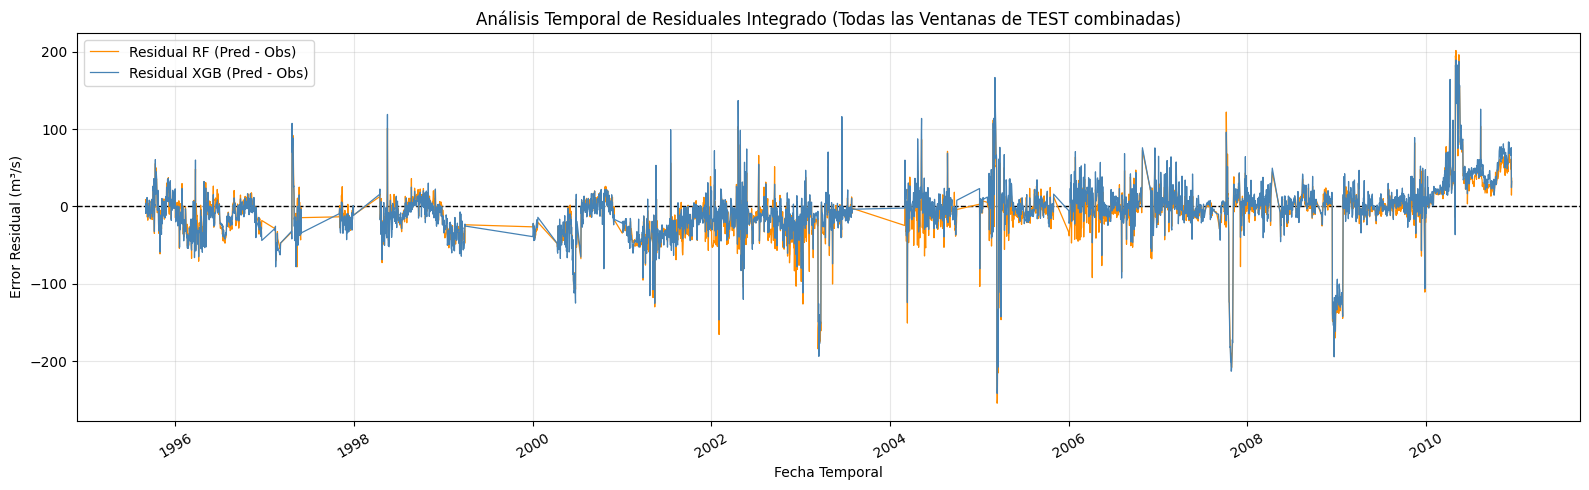


🛡️ PRUEBA ESTADÍSTICA DE RESPALDO GLOBAL (Wilcoxon, Datos Pareados Multiventana)
[RF vs XGB Global] Comparativa de Error Absoluto Acumulado | p = 5.8886e-08
 ➔ Diferencia ESTADÍSTICAMENTE SIGNIFICATIVA: El modelo Random Forest comete menores errores absolutos de forma consistente a lo largo del tiempo.


In [8]:
# ============================================================
# NUEVA CELDA 6 — DIAGNÓSTICO DE SOBREAJUSTE Y ROBUSTEZ TEMPORAL
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import TimeSeriesSplit

try:
    lista_metricas_train, lista_metricas_test
    lista_metricas_train_xgb, lista_metricas_test_xgb
except NameError:
    raise NameError("Por favor, ejecuta primero las nuevas Celdas 4 (RF) y 5 (XGBoost).")

# CORRECCIÓN: Agregamos la lista completa de métricas hidrológicas requeridas
metricas_interes = ["R2", "NSE", "RMSE", "MAE", "PBIAS", "KGE", "IOA"]

# --- 1) TABLA COMPARATIVA GLOBAL (PROMEDIOS WALK-FORWARD) ---
res_rf = {}
res_xgb = {}

for m in metricas_interes:
    vals_tr_rf = [dic[m] for dic in lista_metricas_train]
    vals_te_rf = [dic[m] for dic in lista_metricas_test]
    vals_tr_xgb = [dic[m] for dic in lista_metricas_train_xgb]
    vals_te_xgb = [dic[m] for dic in lista_metricas_test_xgb]

    res_rf[f"{m}_train"] = f"{np.mean(vals_tr_rf):.3f} (±{np.std(vals_tr_rf):.2f})"
    res_rf[f"{m}_test"]  = f"{np.mean(vals_te_rf):.3f} (±{np.std(vals_te_rf):.2f})"
    res_xgb[f"{m}_train"] = f"{np.mean(vals_tr_xgb):.3f} (±{np.std(vals_tr_xgb):.2f})"
    res_xgb[f"{m}_test"]  = f"{np.mean(vals_te_xgb):.3f} (±{np.std(vals_te_xgb):.2f})"

# Calculamos el GAP promedio global para la tabla
gap_rf_promedio = np.mean([dic["R2"] for dic in lista_metricas_train]) - np.mean([dic["R2"] for dic in lista_metricas_test])
gap_xgb_promedio = np.mean([dic["R2"] for dic in lista_metricas_train_xgb]) - np.mean([dic["R2"] for dic in lista_metricas_test_xgb])

# CORRECCIÓN: Agregamos las nuevas métricas MAE, KGE e IOA a las columnas de la tabla comparativa
tabla_comparativa = pd.DataFrame({
    "Modelo": ["Random Forest (RF)", "XGBoost (XGB)"],
    "R2_Train (Promedio)": [res_rf["R2_train"], res_xgb["R2_train"]],
    "R2_Test (Promedio)":  [res_rf["R2_test"],  res_xgb["R2_test"]],
    "NSE_Test (Promedio)": [res_rf["NSE_test"], res_xgb["NSE_test"]],
    "RMSE_Test (Promedio)":[res_rf["RMSE_test"],res_xgb["RMSE_test"]],
    "MAE_Test (Promedio)": [res_rf["MAE_test"], res_xgb["MAE_test"]],
    "PBIAS_Test (Promedio)":[res_rf["PBIAS_test"],res_xgb["PBIAS_test"]],
    "KGE_Test (Promedio)": [res_rf["KGE_test"], res_xgb["KGE_test"]],
    "IOA_Test (Promedio)": [res_rf["IOA_test"], res_xgb["IOA_test"]],
    "GAP_R2_Global":       [f"{gap_rf_promedio:.4f}", f"{gap_xgb_promedio:.4f}"]
})

print("==============================================================")
print("🏆 TABLA COMPARATIVA RESUMIDA RF vs XGB (MÉTRICAS PROMEDIO WALK-FORWARD)")
print("==============================================================")
print(tabla_comparativa.to_string(index=False))

print("\nGuía de lectura del GAP Global (R2_train - R2_test):")
print("  < 0.05            -> Sobreajuste bajo / Generalización óptima")
print("  0.05 - 0.10       -> Sobreajuste moderado, vigilar estabilidad")
print("  > 0.10            -> Sobreajuste alto, riesgo de pérdida de control temporal")


# --- 2) RESIDUALES DE LOS MODELOS FINALES (LOS MISMOS DE LA TABLA) ---
# CORRECCIÓN: antes esta sección re-entrenaba RF y XGB con las 11 variables, sin
# la selección por importancia, y evaluaba modelos distintos a los reportados.
# Ahora usa las predicciones de TEST guardadas en las Celdas 4 y 5, que salen de
# rf_final y xgb_final (entrenados solo con las variables seleccionadas).
try:
    lista_pred_test_rf, lista_pred_test_xgb
except NameError:
    raise NameError("Ejecuta de nuevo las Celdas 4 y 5 (versión corregida) antes de esta celda.")

fechas_test_totales = np.concatenate(lista_fechas_test_rf)
obs_test_totales    = np.concatenate(lista_obs_test_rf)
pred_rf_totales     = np.concatenate(lista_pred_test_rf)
pred_xgb_totales    = np.concatenate(lista_pred_test_xgb)

# Control: RF y XGB deben haberse evaluado sobre los mismos días y valores observados
assert np.array_equal(fechas_test_totales, np.concatenate(lista_fechas_test_xgb)), "Las fechas de TEST de RF y XGB no coinciden."
assert np.allclose(obs_test_totales, np.concatenate(lista_obs_test_xgb)), "Los observados de TEST de RF y XGB no coinciden."

residuales_rf_totales  = pred_rf_totales  - obs_test_totales
residuales_xgb_totales = pred_xgb_totales - obs_test_totales
errores_abs_rf_totales  = np.abs(residuales_rf_totales)
errores_abs_xgb_totales = np.abs(residuales_xgb_totales)
print(f"Días de TEST evaluados (3 ventanas): {len(obs_test_totales)}")

fig, ax = plt.subplots(figsize=(16, 5))
ax.axhline(0, color="black", lw=1, linestyle="--")
ax.plot(fechas_test_totales, residuales_rf_totales, color="darkorange", lw=0.9, label="Residual RF (Pred - Obs)")
ax.plot(fechas_test_totales, residuales_xgb_totales, color="steelblue", lw=0.9, label="Residual XGB (Pred - Obs)")
ax.set_title("Análisis Temporal de Residuales Integrado (Todas las Ventanas de TEST combinadas)", fontsize=12)
ax.set_xlabel("Fecha Temporal"); ax.set_ylabel("Error Residual (m³/s)")
ax.legend(); ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()


# --- 3) PRUEBA ESTADÍSTICA DE ROBUSTEZ FINAL (Wilcoxon en Ventanas) ---
print("\n" + "="*70)
print("🛡️ PRUEBA ESTADÍSTICA DE RESPALDO GLOBAL (Wilcoxon, Datos Pareados Multiventana)")
print("="*70)

_, p_rf_vs_xgb_global = wilcoxon(errores_abs_rf_totales, errores_abs_xgb_totales)

print(f"[RF vs XGB Global] Comparativa de Error Absoluto Acumulado | p = {p_rf_vs_xgb_global:.4e}")
if p_rf_vs_xgb_global < 0.05:
    mean_err_xgb = np.mean(errores_abs_xgb_totales)
    mean_err_rf  = np.mean(errores_abs_rf_totales)
    mejor = "XGBoost" if mean_err_xgb < mean_err_rf else "Random Forest"
    print(f" ➔ Diferencia ESTADÍSTICAMENTE SIGNIFICATIVA: El modelo {mejor} comete menores errores absolutos de forma consistente a lo largo del tiempo.")
else:
    print(" ➔ La diferencia operativa entre RF y XGBoost NO es estadísticamente significativa bajo el esquema Walk-Forward.")


## Celda 7 — Prediccion fuera de muestra (2011-2025)

       Variable  Importancia  Importancia_norm  Acumulada
     COTOCA_NIV     0.461141          0.461141   0.461141
     COTOCA_QMD     0.284061          0.284061   0.745201
COTOCA_NIV_LAG1     0.114043          0.114043   0.859244
COTOCA_QMD_LAG1     0.062858          0.062858   0.922102
     SABANA_QMD     0.053051          0.053051   0.975153
     SABANA_NIV     0.015183          0.015183   0.990336
SABANA_QMD_LAG1     0.006484          0.006484   0.996820
SABANA_NIV_LAG1     0.002900          0.002900   0.999719
DOCTRINA_PRECIP     0.000124          0.000124   0.999844
   CHIMA_PRECIP     0.000096          0.000096   0.999940
   MOMIL_PRECIP     0.000060          0.000060   1.000000
-> 6 variable(s) seleccionadas (umbral 98%): ['COTOCA_NIV', 'COTOCA_QMD', 'COTOCA_NIV_LAG1', 'COTOCA_QMD_LAG1', 'SABANA_QMD', 'SABANA_NIV']
       Variable  Importancia  Importancia_norm  Acumulada
     COTOCA_NIV     0.770963          0.770963   0.770963
     COTOCA_QMD     0.104533          0.104533  

Saving COTOCA_NIV.csv to COTOCA_NIV.csv
Saving COTOCA_QMD.csv to COTOCA_QMD.csv
Saving SABANA_NIV.csv to SABANA_NIV.csv
Saving SABANA_QMD.csv to SABANA_QMD.csv
COTOCA_NIV         huecos antes de imputar: 71
COTOCA_QMD         huecos antes de imputar: 71
SABANA_NIV         huecos antes de imputar: 192
SABANA_QMD         huecos antes de imputar: 165

Días a predecir: 5478 (2011-01-02 -> 2025-12-31)

CHEQUEO DE EXTRAPOLACIÓN (% de días 2011-2025 fuera del rango visto en el último TRAIN):
  COTOCA_NIV         rango train=[83.0, 599.0]  ->  2.1% de los días futuros está fuera de ese rango
  COTOCA_NIV_LAG1    rango train=[83.0, 599.0]  ->  2.1% de los días futuros está fuera de ese rango
  COTOCA_QMD         rango train=[38.8, 770.2]  ->  0.0% de los días futuros está fuera de ese rango
  COTOCA_QMD_LAG1    rango train=[38.8, 770.2]  ->  0.0% de los días futuros está fuera de ese rango
  SABANA_NIV         rango train=[106.0, 661.0]  ->  2.7% de los días futuros está fuera de ese rango
  SA

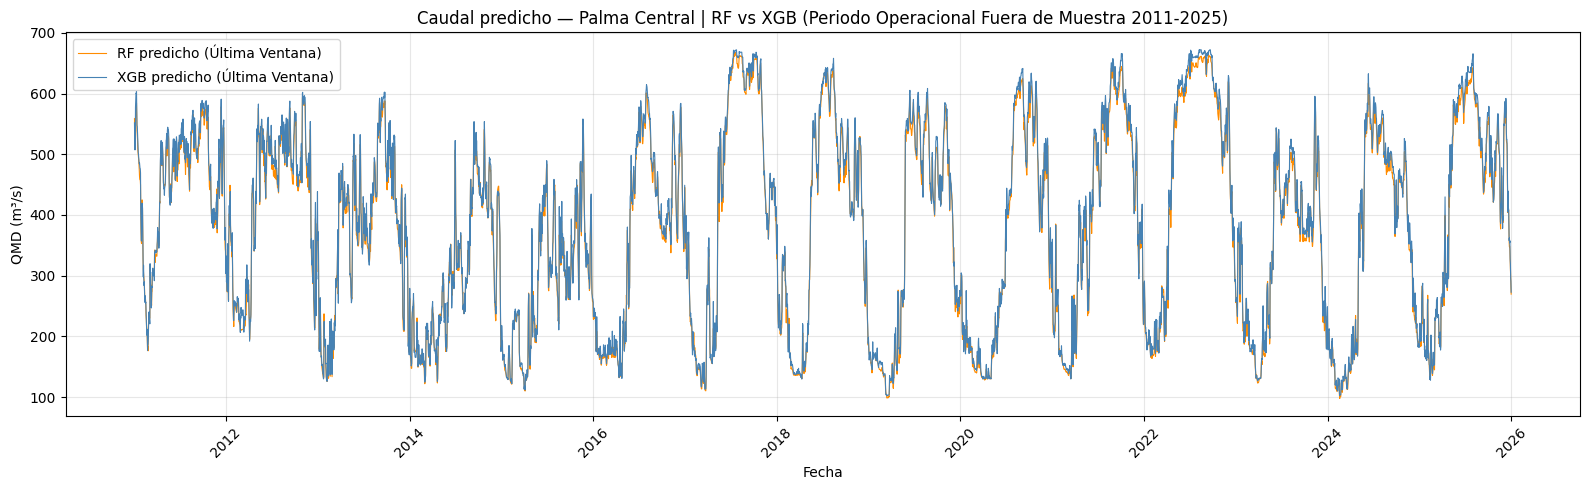

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


prediccion_2011_2025.xlsx exportado exitosamente


In [9]:
# ============================================================
# NUEVA CELDA 7 — PREDICCIÓN FUERA DE MUESTRA (2011-2025)
# ============================================================
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit

try:
    lista_mejores_parametros
    lista_mejores_parametros_xgb
    df_ml
except NameError:
    raise NameError("Por favor, ejecuta las nuevas Celdas 4, 5 y 6 antes de correr la predicción futura.")

# --- 1) RECUPERAR LA ÚLTIMA GENERACIÓN TEMPORAL (MÁXIMA INFORMACIÓN) ---
tscv_test = TimeSeriesSplit(n_splits=3, gap=14)
X_completo = df_ml[PREDICTORES]
y_completo = df_ml[TARGET_COL]

# Extraemos los índices del último corte de la validación cruzada walk-forward
for train_index, test_index in tscv_test.split(X_completo):
    ultimo_train_idx = train_index

X_train_ultimo = X_completo.iloc[ultimo_train_idx]
y_train_ultimo = y_completo.iloc[ultimo_train_idx]

# CORRECCIÓN REPRODUCIBILIDAD: Se añade fixed random_state=42 en todos los re-entrenamientos operacionales
# Random Forest Último
rf_completo_u = RandomForestRegressor(**lista_mejores_parametros[-1], random_state=42, n_jobs=-1)
rf_completo_u.fit(X_train_ultimo, y_train_ultimo)
VARS_RF_U, _ = seleccionar_variables_por_importancia(rf_completo_u, PREDICTORES, umbral=0.98)

rf_final_u = RandomForestRegressor(**lista_mejores_parametros[-1], random_state=42, n_jobs=-1)
rf_final_u.fit(X_train_ultimo[VARS_RF_U], y_train_ultimo)

# XGBoost Último
xgb_completo_u = XGBRegressor(**lista_mejores_parametros_xgb[-1], random_state=42, n_jobs=-1,
                               objective="reg:squarederror", importance_type="gain")
xgb_completo_u.fit(X_train_ultimo, y_train_ultimo)
VARS_XGB_U, _ = seleccionar_variables_por_importancia(xgb_completo_u, PREDICTORES, umbral=0.98)

xgb_final_u = XGBRegressor(**lista_mejores_parametros_xgb[-1], random_state=42, n_jobs=-1,
                             objective="reg:squarederror", importance_type="gain")
xgb_final_u.fit(X_train_ultimo[VARS_XGB_U], y_train_ultimo)

# Consolidamos el universo de variables requeridas por los modelos finales de la última ventana
VARS_REQUERIDAS_TOTALES = set(VARS_RF_U) | set(VARS_XGB_U)
VARS_BASE = sorted(set(v.replace("_LAG1", "") for v in VARS_REQUERIDAS_TOTALES))


# --- 2) CARGA Y PROCESAMIENTO DE ARCHIVOS FUTUROS ---
print(f"Sube los CSV del periodo 2011-2025 para: {', '.join(VARS_BASE)}")
subidos = files.upload()
subidos_norm = {re.sub(r"\s*\(\d+\)\s*$", "", n.replace(".csv", "").replace(".CSV", "")).strip(): c
                for n, c in subidos.items()}

# Lectura e imputación utilizando tus funciones de las celdas iniciales
dfs_pred = {v: leer_csv(subidos_norm[v]).rename(columns={"Valor": v}) for v in VARS_BASE}
rango = pd.date_range(min(d["Fecha"].min() for d in dfs_pred.values()),
                       max(d["Fecha"].max() for d in dfs_pred.values()), freq="D")

df_futuro = pd.DataFrame({"Fecha": rango})
for v, d in dfs_pred.items():
    s = d.set_index("Fecha")[v].reindex(rango)
    print(f"{v:<18} huecos antes de imputar: {s.isna().sum()}")
    df_futuro[v] = imputar(s).values

# Construcción de variables con retraso (LAG1) si son requeridas
for v in VARS_REQUERIDAS_TOTALES:
    if v.endswith("_LAG1") and v not in df_futuro.columns:
        df_futuro[v] = df_futuro[v.replace("_LAG1", "")].shift(1)

df_futuro = df_futuro.dropna(subset=list(VARS_REQUERIDAS_TOTALES)).reset_index(drop=True)
print(f"\nDías a predecir: {len(df_futuro)} ({df_futuro['Fecha'].min().date()} -> {df_futuro['Fecha'].max().date()})")


# --- 3) CHEQUEO DE EXTRAPOLACIÓN (CONTRA EL ÚLTIMO HISTORIAL VISTO) ---
print("\nCHEQUEO DE EXTRAPOLACIÓN (% de días 2011-2025 fuera del rango visto en el último TRAIN):")
for v in sorted(VARS_REQUERIDAS_TOTALES):
    if v not in df_futuro.columns or v not in X_train_ultimo.columns:
        continue
    lo, hi = X_train_ultimo[v].min(), X_train_ultimo[v].max()
    fuera = ((df_futuro[v] < lo) | (df_futuro[v] > hi)).mean() * 100
    print(f"  {v:<18} rango train=[{lo:.1f}, {hi:.1f}]  ->  {fuera:.1f}% de los días futuros está fuera de ese rango")


# --- 4) EJECUCIÓN DEL PRONÓSTICO FUERA DE MUESTRA ---
df_futuro["QMD_RF_PREDICHO"]  = rf_final_u.predict(df_futuro[VARS_RF_U])
df_futuro["QMD_XGB_PREDICHO"] = xgb_final_u.predict(df_futuro[VARS_XGB_U])

# Gráfica de proyección temporal directa
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(df_futuro["Fecha"], df_futuro["QMD_RF_PREDICHO"],  color="darkorange", lw=0.8, label="RF predicho (Última Ventana)")
ax.plot(df_futuro["Fecha"], df_futuro["QMD_XGB_PREDICHO"], color="steelblue",  lw=0.8, label="XGB predicho (Última Ventana)")
ax.set_title("Caudal predicho — Palma Central | RF vs XGB (Periodo Operacional Fuera de Muestra 2011-2025)", fontsize=12)
ax.set_xlabel("Fecha"); ax.set_ylabel("QMD (m³/s)")
ax.legend(); ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


# --- 5) EXPORTAR RESULTADOS ---
df_futuro.to_excel("prediccion_2011_2025.xlsx", index=False)
files.download("prediccion_2011_2025.xlsx")
print("\nprediccion_2011_2025.xlsx exportado exitosamente")



## Celda 8 — Resumen final de metricas

In [13]:
# ============================================================
# NUEVA CELDA 8 — RESUMEN FINAL DE METRICAS (PROMEDIOS WALK-FORWARD)
# Tabla única de cierre exportable y con estilos visuales aplicados.
# ============================================================
import pandas as pd
import numpy as np
from google.colab import files

try:
    lista_metricas_train, lista_metricas_test
    lista_metricas_train_xgb, lista_metricas_test_xgb
except NameError:
    raise NameError("Por favor, ejecuta primero las nuevas Celdas 4 (RF) y 5 (XGBoost).")

# --- 1) CÁLCULO DE PROMEDIOS Y DESVIACIONES PARA EXCEL Y ESTILOS ---
def obtener_estadisticos(lista_diccionarios, metrica):
    vals = [d[metrica] for d in lista_diccionarios]
    return np.mean(vals), np.std(vals)

# CORRECCIÓN: Extracción de todas las métricas requeridas para el modelo Random Forest (RF)
mean_r2_tr_rf, _    = obtener_estadisticos(lista_metricas_train, "R2")
mean_r2_te_rf, _    = obtener_estadisticos(lista_metricas_test, "R2")
mean_nse_tr_rf, _   = obtener_estadisticos(lista_metricas_train, "NSE")
mean_nse_te_rf, _   = obtener_estadisticos(lista_metricas_test, "NSE")
mean_rmse_tr_rf, _  = obtener_estadisticos(lista_metricas_train, "RMSE")
mean_rmse_te_rf, _  = obtener_estadisticos(lista_metricas_test, "RMSE")
mean_mae_tr_rf, _   = obtener_estadisticos(lista_metricas_train, "MAE")
mean_mae_te_rf, _   = obtener_estadisticos(lista_metricas_test, "MAE")
mean_pbias_tr_rf, _ = obtener_estadisticos(lista_metricas_train, "PBIAS")
mean_pbias_te_rf, _ = obtener_estadisticos(lista_metricas_test, "PBIAS")
mean_kge_tr_rf, _   = obtener_estadisticos(lista_metricas_train, "KGE")
mean_kge_te_rf, _   = obtener_estadisticos(lista_metricas_test, "KGE")
mean_ioa_tr_rf, _   = obtener_estadisticos(lista_metricas_train, "IOA")
mean_ioa_te_rf, _   = obtener_estadisticos(lista_metricas_test, "IOA")
gap_rf_mean         = mean_r2_tr_rf - mean_r2_te_rf

# CORRECCIÓN: Extracción de todas las métricas requeridas para el modelo XGBoost (XGB)
mean_r2_tr_xgb, _    = obtener_estadisticos(lista_metricas_train_xgb, "R2")
mean_r2_te_xgb, _    = obtener_estadisticos(lista_metricas_test_xgb, "R2")
mean_nse_tr_xgb, _   = obtener_estadisticos(lista_metricas_train_xgb, "NSE")
mean_nse_te_xgb, _   = obtener_estadisticos(lista_metricas_test_xgb, "NSE")
mean_rmse_tr_xgb, _  = obtener_estadisticos(lista_metricas_train_xgb, "RMSE")
mean_rmse_te_xgb, _  = obtener_estadisticos(lista_metricas_test_xgb, "RMSE")
mean_mae_tr_xgb, _   = obtener_estadisticos(lista_metricas_train_xgb, "MAE")
mean_mae_te_xgb, _   = obtener_estadisticos(lista_metricas_test_xgb, "MAE")
mean_pbias_tr_xgb, _ = obtener_estadisticos(lista_metricas_train_xgb, "PBIAS")
mean_pbias_te_xgb, _ = obtener_estadisticos(lista_metricas_test_xgb, "PBIAS")
mean_kge_tr_xgb, _   = obtener_estadisticos(lista_metricas_train_xgb, "KGE")
mean_kge_te_xgb, _   = obtener_estadisticos(lista_metricas_test_xgb, "KGE")
mean_ioa_tr_xgb, _   = obtener_estadisticos(lista_metricas_train_xgb, "IOA")
mean_ioa_te_xgb, _   = obtener_estadisticos(lista_metricas_test_xgb, "IOA")
gap_xgb_mean         = mean_r2_tr_xgb - mean_r2_te_xgb


# --- 2) CONSTRUCCIÓN DE LA TABLA TEXTUAL (FORMATO TESIS CON VARIABILIDAD) ---
rf_strings = {}
xgb_strings = {}
metricas_lista = ["R2", "NSE", "RMSE", "MAE", "PBIAS", "KGE", "IOA"]

for m in metricas_lista:
    m_tr_rf, s_tr_rf = obtener_estadisticos(lista_metricas_train, m)
    m_te_rf, s_te_rf = obtener_estadisticos(lista_metricas_test, m)
    m_tr_xgb, s_tr_xgb = obtener_estadisticos(lista_metricas_train_xgb, m)
    m_te_xgb, s_te_xgb = obtener_estadisticos(lista_metricas_test_xgb, m)

    rf_strings[f"{m}_train"] = f"{m_tr_rf:.3f} (±{s_tr_rf:.2f})"
    rf_strings[f"{m}_test"]  = f"{m_te_rf:.3f} (±{s_te_rf:.2f})"
    xgb_strings[f"{m}_train"] = f"{m_tr_xgb:.3f} (±{s_tr_xgb:.2f})"
    xgb_strings[f"{m}_test"]  = f"{m_te_xgb:.3f} (±{s_te_xgb:.2f})"

resumen_tesis = pd.DataFrame({
    "Modelo":             ["RF", "XGB"],
    "R2_train":           [rf_strings["R2_train"],    xgb_strings["R2_train"]],
    "R2_test":            [rf_strings["R2_test"],     xgb_strings["R2_test"]],
    "NSE_train":          [rf_strings["NSE_train"],   xgb_strings["NSE_train"]],
    "NSE_test":           [rf_strings["NSE_test"],    xgb_strings["NSE_test"]],
    "RMSE_train_(m3/s)":  [rf_strings["RMSE_train"],  xgb_strings["RMSE_train"]],
    "RMSE_test_(m3/s)":   [rf_strings["RMSE_test"],   xgb_strings["RMSE_test"]],
    "MAE_train_(m3/s)":   [rf_strings["MAE_train"],   xgb_strings["MAE_train"]],
    "MAE_test_(m3/s)":    [rf_strings["MAE_test"],    xgb_strings["MAE_test"]],
    "PBIAS_train_%":      [rf_strings["PBIAS_train"], xgb_strings["PBIAS_train"]],
    "PBIAS_test_%":       [rf_strings["PBIAS_test"],  xgb_strings["PBIAS_test"]],
    "KGE_train":          [rf_strings["KGE_train"],   xgb_strings["KGE_train"]],
    "KGE_test":           [rf_strings["KGE_test"],    xgb_strings["KGE_test"]],
    "IOA_train":          [rf_strings["IOA_train"],   xgb_strings["IOA_train"]],
    "IOA_test":           [rf_strings["IOA_test"],    xgb_strings["IOA_test"]],
    "GAP_(R2train-test)": [f"{gap_rf_mean:.4f}",       f"{gap_xgb_mean:.4f}"],
})

print("="*100)
print("🏆 RESUMEN FINAL DE MÉTRICAS CONSOLIDADAS EN FORMATO HORIZONTAL (WALK-FORWARD)")
print("="*100)
print(resumen_tesis.set_index("Modelo").T.to_string())


# --- 3) CONSTRUCCIÓN DE LA TABLA NUMÉRICA (PARA EXCEL Y ESTILOS) ---
resumen_final_num = pd.DataFrame({
    "Modelo":             ["RF", "XGB"],
    "R2_train":           [mean_r2_tr_rf,    mean_r2_tr_xgb],
    "R2_test":            [mean_r2_te_rf,    mean_r2_te_xgb],
    "NSE_train":          [mean_nse_tr_rf,   mean_nse_tr_xgb],
    "NSE_test":           [mean_nse_te_rf,   mean_nse_te_xgb],
    "RMSE_train_(m3/s)":  [mean_rmse_tr_rf,  mean_rmse_tr_xgb],
    "RMSE_test_(m3/s)":   [mean_rmse_te_rf,  mean_rmse_te_xgb],
    "MAE_train_(m3/s)":   [mean_mae_tr_rf,   mean_mae_tr_xgb],
    "MAE_test_(m3/s)":    [mean_mae_te_rf,   mean_mae_te_xgb],
    "PBIAS_train_%":      [mean_pbias_tr_rf, mean_pbias_tr_xgb],
    "PBIAS_test_%":       [mean_pbias_te_rf, mean_pbias_te_xgb],
    "KGE_train":          [mean_kge_tr_rf,   mean_kge_tr_xgb],
    "KGE_test":           [mean_kge_te_rf,   mean_kge_te_xgb],
    "IOA_train":          [mean_ioa_tr_rf,   mean_ioa_tr_xgb],
    "IOA_test":           [mean_ioa_te_rf,   mean_ioa_te_xgb],
    "GAP_(R2train-test)": [gap_rf_mean,      gap_xgb_mean],
}).round(4)

# Exportar a Excel descargable de forma automática
resumen_final_num.to_excel("resumen_metricas_RF_XGB.xlsx", index=False)
files.download("resumen_metricas_RF_XGB.xlsx")
print("\n💾 resumen_metricas_RF_XGB.xlsx exportado exitosamente.")


# --- 4) DESPLIEGUE VISUAL CON GRADIENTES DE COLOR (DATOS PROMEDIO) ---
print("\n🖼️ VISTA DE RENDIMIENTO RELATIVO (PROMEDIOS EN COLOR):")
display(resumen_final_num.style.background_gradient(
    subset=["R2_test", "NSE_test", "KGE_test", "IOA_test"], cmap="Greens"
).background_gradient(
    subset=["RMSE_test_(m3/s)", "MAE_test_(m3/s)", "GAP_(R2train-test)"], cmap="Reds_r"
))


🏆 RESUMEN FINAL DE MÉTRICAS CONSOLIDADAS EN FORMATO HORIZONTAL (WALK-FORWARD)
Modelo                          RF             XGB
R2_train             0.995 (±0.00)   0.998 (±0.00)
R2_test              0.957 (±0.02)   0.956 (±0.02)
NSE_train            0.995 (±0.00)   0.998 (±0.00)
NSE_test             0.948 (±0.01)   0.947 (±0.01)
RMSE_train_(m3/s)   11.352 (±3.51)   7.160 (±1.68)
RMSE_test_(m3/s)    35.351 (±5.44)  35.507 (±6.05)
MAE_train_(m3/s)     6.565 (±1.58)   4.642 (±0.97)
MAE_test_(m3/s)     22.318 (±0.60)  22.942 (±2.89)
PBIAS_train_%       -0.015 (±0.01)  -0.003 (±0.00)
PBIAS_test_%        -2.140 (±2.28)  -1.405 (±2.63)
KGE_train            0.994 (±0.00)   0.991 (±0.00)
KGE_test             0.947 (±0.02)   0.947 (±0.02)
IOA_train            0.999 (±0.00)   0.999 (±0.00)
IOA_test             0.987 (±0.00)   0.987 (±0.00)
GAP_(R2train-test)          0.0375          0.0422


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


💾 resumen_metricas_RF_XGB.xlsx exportado exitosamente.

🖼️ VISTA DE RENDIMIENTO RELATIVO (PROMEDIOS EN COLOR):


,Modelo,R2_train,R2_test,NSE_train,NSE_test,RMSE_train_(m3/s),RMSE_test_(m3/s),MAE_train_(m3/s),MAE_test_(m3/s),PBIAS_train_%,PBIAS_test_%,KGE_train,KGE_test,IOA_train,IOA_test,GAP_(R2train-test)
0,RF,0.994700,0.957200,0.994700,0.947700,11.352300,35.351300,6.565400,22.317700,-0.014700,-2.139900,0.993700,0.946600,0.998700,0.987000,0.037500
1,XGB,0.998100,0.955900,0.998000,0.947000,7.159600,35.506800,4.642200,22.942400,-0.002600,-1.405100,0.991400,0.947400,0.999500,0.986700,0.042200


## Celda 9 — Visualización interactiva de RF y XGB (train, test y predicción)

In [11]:
# ============================================================
# CELDA 9 — VISUALIZACIÓN INTERACTIVA DE RF Y XGB (TRAIN, TEST Y PREDICCIÓN)
# Requiere las Celdas 4, 5 y 7. No entrena nada: solo dibuja lo ya calculado.
# Uso: menú de arriba = elegir ventana; clic en la leyenda = mostrar u ocultar
# una serie; arrastrar = zoom; doble clic = volver a la vista completa;
# barra inferior = desplazarse en el tiempo.
# ============================================================
import plotly.graph_objects as go

try:
    lista_pred_train_rf, lista_pred_train_xgb, lista_pred_test_rf, lista_pred_test_xgb
except NameError:
    raise NameError("Ejecuta de nuevo las Celdas 4 y 5 (versión corregida) antes de esta celda.")

COLOR_RF, COLOR_XGB = "darkorange", "steelblue"

# --- 1) TRAIN y TEST por ventana walk-forward ---
fig_v = go.Figure()
trazas_por_ventana = []
for v in range(len(lista_pred_test_rf)):
    visible = (v == len(lista_pred_test_rf) - 1)   # se abre en la última ventana
    ft, fe = lista_fechas_train_rf[v], lista_fechas_test_rf[v]
    series = [
        ("Observado", np.concatenate([ft, fe]),
         np.concatenate([lista_obs_train_rf[v], lista_obs_test_rf[v]]), dict(color="black", width=1.2)),
        ("RF — train",  ft, lista_pred_train_rf[v],  dict(color=COLOR_RF,  width=1, dash="dot")),
        ("RF — test",   fe, lista_pred_test_rf[v],   dict(color=COLOR_RF,  width=1.5)),
        ("XGB — train", ft, lista_pred_train_xgb[v], dict(color=COLOR_XGB, width=1, dash="dot")),
        ("XGB — test",  fe, lista_pred_test_xgb[v],  dict(color=COLOR_XGB, width=1.5)),
    ]
    idx = []
    for nombre, x, y, linea in series:
        fig_v.add_trace(go.Scattergl(x=x, y=y, name=nombre, mode="lines", line=linea, visible=visible,
                                     hovertemplate=f"{nombre}<br>%{{x|%Y-%m-%d}}: %{{y:.1f}} m³/s<extra></extra>"))
        idx.append(len(fig_v.data) - 1)
    trazas_por_ventana.append((idx, fe[0]))

botones = []
for v, (idx, inicio_test) in enumerate(trazas_por_ventana):
    vis = [False] * len(fig_v.data)
    for i in idx: vis[i] = True
    m_rf, m_xgb = lista_metricas_test[v], lista_metricas_test_xgb[v]
    botones.append(dict(label=f"Ventana {v+1}", method="update",
        args=[{"visible": vis},
              {"title": f"Ventana {v+1} — TEST: NSE RF={m_rf['NSE']:.3f}, XGB={m_xgb['NSE']:.3f} | "
                        f"RMSE RF={m_rf['RMSE']:.1f}, XGB={m_xgb['RMSE']:.1f} m³/s",
               "shapes": [dict(type="line", x0=inicio_test, x1=inicio_test, yref="paper", y0=0, y1=1,
                               line=dict(color="gray", dash="dash"))]}]))

ultima = len(trazas_por_ventana) - 1
fig_v.update_layout(
    updatemenus=[dict(buttons=botones, direction="down", x=0, y=1.18, xanchor="left", active=ultima)],
    title=botones[ultima]["args"][1]["title"], shapes=botones[ultima]["args"][1]["shapes"],
    template="plotly_white", height=600, hovermode="x unified",
    yaxis_title="QMD (m³/s)", xaxis=dict(rangeslider=dict(visible=True), type="date"),
    legend=dict(orientation="h", y=-0.35))
fig_v.show()
fig_v.write_html("rf_xgb_train_test_interactivo.html")

# --- 2) PREDICCIÓN 2011-2025 junto al observado 1991-2010 ---
try:
    df_futuro
    fig_p = go.Figure()
    fig_p.add_trace(go.Scattergl(x=df_ml["Fecha"], y=df_ml[TARGET_COL], name="Observado 1991-2010",
                                 mode="lines", line=dict(color="black", width=1)))
    fig_p.add_trace(go.Scattergl(x=df_futuro["Fecha"], y=df_futuro["QMD_RF_PREDICHO"], name="RF predicho",
                                 mode="lines", line=dict(color=COLOR_RF, width=1)))
    fig_p.add_trace(go.Scattergl(x=df_futuro["Fecha"], y=df_futuro["QMD_XGB_PREDICHO"], name="XGB predicho",
                                 mode="lines", line=dict(color=COLOR_XGB, width=1)))
    fig_p.update_layout(title="Caudal Palma Central — observado 1991-2010 y predicho 2011-2025",
                        template="plotly_white", height=550, hovermode="x unified", yaxis_title="QMD (m³/s)",
                        xaxis=dict(rangeslider=dict(visible=True), type="date"),
                        legend=dict(orientation="h", y=-0.35))
    fig_p.show()
    fig_p.write_html("prediccion_2011_2025_interactivo.html")

    # Mapa de faltantes de las entradas 2011-2025 ANTES de imputar
    df_crudo_fut = pd.DataFrame({v: d.set_index("Fecha")[v].reindex(rango) for v, d in dfs_pred.items()})
    mapa_faltantes_interactivo(df_crudo_fut, "Entradas 2011-2025 antes de imputar — azul = con dato, gris = imputado"
                               ).write_html("mapa_faltantes_2011_2025.html")
except NameError:
    print("Sin Celda 7: se omite la gráfica de predicción 2011-2025.")

print("Archivos HTML guardados en la carpeta de Colab (panel de archivos, a la izquierda).")


Archivos HTML guardados en la carpeta de Colab (panel de archivos, a la izquierda).


## Celda 10 — Animaciones GIF (ajuste por número de árboles y ventanas walk-forward)

In [12]:
# ============================================================
# CELDA 10 — ANIMACIONES GIF (PARA PRESENTACIONES)
# Requiere las Celdas 4 y 5. No entrena nada nuevo: reutiliza los modelos
# finales de cada ventana guardados en esas celdas.
#   GIF 1 y 2: cómo se va ajustando RF y XGB en TEST a medida que se suman
#              árboles (ventana walk-forward elegida abajo).
#   GIF 3:     las 3 ventanas walk-forward, una tras otra (train, test y error).
# Los GIF se guardan en Colab y se descargan al final.
# ============================================================
import warnings
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter
from google.colab import files

try:
    lista_modelos_rf, lista_modelos_xgb
except NameError:
    raise NameError("Ejecuta de nuevo las Celdas 4 y 5 (versión corregida) antes de esta celda.")

VENTANA_GIF = len(lista_modelos_rf)   # ventana a animar (1, 2 o 3); por defecto la última
COLOR_RF, COLOR_XGB = "darkorange", "steelblue"
v = VENTANA_GIF - 1
fechas_te = pd.to_datetime(lista_fechas_test_rf[v])
obs_te = lista_obs_test_rf[v]
_, test_idx_v = list(TimeSeriesSplit(n_splits=len(lista_modelos_rf), gap=14).split(df_ml))[v]
X_te_v = df_ml.iloc[test_idx_v]


# ------------------------------------------------------------
# FUNCION: pasos_de_arboles
# ------------------------------------------------------------
# Devuelve los números de árboles que se muestran en cada cuadro del GIF:
# muy seguidos al principio (donde el modelo cambia mucho) y más espaciados
# al final (donde ya casi no cambia).
def pasos_de_arboles(n_total, n_cuadros=30):
    pasos = np.unique(np.geomspace(1, n_total, n_cuadros).round().astype(int))
    return pasos


# ------------------------------------------------------------
# FUNCION: predicciones_por_numero_de_arboles
# ------------------------------------------------------------
# Para cada número k de árboles, calcula la predicción que daría el modelo
# usando solo sus primeros k árboles.
#  - RF: promedio de los primeros k árboles (así combina RF sus árboles).
#  - XGB: suma de los primeros k árboles (iteration_range).
def predicciones_por_numero_de_arboles(modelo, X, tipo, pasos):
    if tipo == "RF":
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            por_arbol = np.array([t.predict(X.to_numpy(dtype=np.float32)) for t in modelo.estimators_])
        acumulado = np.cumsum(por_arbol, axis=0)
        return {k: acumulado[k - 1] / k for k in pasos}
    return {k: modelo.predict(X, iteration_range=(0, int(k))) for k in pasos}


# ------------------------------------------------------------
# FUNCION: gif_ajuste_por_arboles
# ------------------------------------------------------------
# Arma el GIF: arriba, observado vs predicho en TEST; abajo, la curva de
# RMSE contra número de árboles, que se va dibujando cuadro a cuadro.
def gif_ajuste_por_arboles(modelo, variables, tipo, color, archivo):
    n_total = len(modelo.estimators_) if tipo == "RF" else modelo.get_booster().num_boosted_rounds()
    pasos = pasos_de_arboles(n_total)
    preds = predicciones_por_numero_de_arboles(modelo, X_te_v[variables], tipo, pasos)
    rmse = [np.sqrt(np.mean((preds[k] - obs_te) ** 2)) for k in pasos]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 6.5), gridspec_kw={"height_ratios": [2.2, 1]})
    ax1.plot(fechas_te, obs_te, "k", lw=1, label="Observado")
    linea, = ax1.plot(fechas_te, preds[pasos[0]], color=color, lw=1.2, label=f"{tipo} predicho")
    ax1.set_ylabel("QMD (m³/s)"); ax1.legend(loc="upper right"); ax1.grid(alpha=0.3)
    ax1.set_ylim(min(obs_te.min(), min(p.min() for p in preds.values())) * 0.95,
                 max(obs_te.max(), max(p.max() for p in preds.values())) * 1.05)
    curva, = ax2.plot([], [], "o-", color=color, ms=3, lw=1.2)
    ax2.set_xscale("log"); ax2.set_xlim(0.8, n_total * 1.25)
    ax2.set_ylim(0, max(rmse) * 1.1); ax2.grid(alpha=0.3)
    ax2.set_xlabel("Número de árboles (escala log)"); ax2.set_ylabel("RMSE test (m³/s)")
    titulo = fig.suptitle("", x=0.01, ha="left", fontsize=12)
    plt.tight_layout(rect=(0, 0, 1, 0.95))

    def cuadro(i):
        k = pasos[i]
        linea.set_ydata(preds[k])
        curva.set_data(pasos[:i + 1], rmse[:i + 1])
        titulo.set_text(f"{tipo} — Ventana {VENTANA_GIF} (TEST) | {k} de {n_total} árboles | "
                        f"NSE = {nse(obs_te, preds[k]):.3f} | RMSE = {rmse[i]:.1f} m³/s")
        return linea, curva, titulo

    # Se repite el último cuadro para que el GIF se detenga un momento al final
    orden = list(range(len(pasos))) + [len(pasos) - 1] * 8
    anim = FuncAnimation(fig, cuadro, frames=orden, blit=False)
    anim.save(archivo, writer=PillowWriter(fps=4), dpi=90)
    plt.close(fig)
    print(f"{archivo} guardado ({len(pasos)} cuadros).")


gif_ajuste_por_arboles(lista_modelos_rf[v],  lista_vars_rf[v],  "RF",  COLOR_RF,  "rf_ajuste_por_arboles.gif")
gif_ajuste_por_arboles(lista_modelos_xgb[v], lista_vars_xgb[v], "XGB", COLOR_XGB, "xgb_ajuste_por_arboles.gif")


# --- GIF 3: las 3 ventanas walk-forward, una tras otra ---
fig, ax = plt.subplots(figsize=(13, 5))
fig.subplots_adjust(left=0.06, right=0.98, top=0.84, bottom=0.08)
def cuadro_ventana(i):
    ax.clear()
    ax.plot(df_ml["Fecha"], df_ml[TARGET_COL], color="lightgray", lw=0.8, label="Observado (fuera de la ventana)")
    ft, fe = pd.to_datetime(lista_fechas_train_rf[i]), pd.to_datetime(lista_fechas_test_rf[i])
    ax.axvspan(ft[0], ft[-1], color="gray", alpha=0.08)
    ax.axvspan(fe[0], fe[-1], color="gold", alpha=0.12)
    ax.plot(ft, lista_obs_train_rf[i], "k", lw=0.8, label="Observado train")
    ax.plot(fe, lista_obs_test_rf[i], "k", lw=1.2, label="Observado test")
    ax.plot(fe, lista_pred_test_rf[i],  color=COLOR_RF,  lw=1, label="RF predicho (test)")
    ax.plot(fe, lista_pred_test_xgb[i], color=COLOR_XGB, lw=1, label="XGB predicho (test)")
    m_rf, m_xgb = lista_metricas_test[i], lista_metricas_test_xgb[i]
    ax.set_title(f"Validación walk-forward — Ventana {i+1} de {len(lista_modelos_rf)} | "
                 f"train {ft[0]:%Y-%m} a {ft[-1]:%Y-%m}, test {fe[0]:%Y-%m} a {fe[-1]:%Y-%m}\n"
                 f"NSE test: RF = {m_rf['NSE']:.3f}, XGB = {m_xgb['NSE']:.3f} | "
                 f"RMSE test: RF = {m_rf['RMSE']:.1f}, XGB = {m_xgb['RMSE']:.1f} m³/s", loc="left", fontsize=11)
    ax.set_ylabel("QMD (m³/s)"); ax.grid(alpha=0.3); ax.legend(loc="upper left", fontsize=8, ncol=3)
    return []

orden = [i for i in range(len(lista_modelos_rf)) for _ in range(6)]   # cada ventana ~3 s
anim = FuncAnimation(fig, cuadro_ventana, frames=orden, blit=False)
anim.save("walk_forward_ventanas.gif", writer=PillowWriter(fps=2), dpi=90)
plt.close(fig)
print("walk_forward_ventanas.gif guardado.")

for g in ["rf_ajuste_por_arboles.gif", "xgb_ajuste_por_arboles.gif", "walk_forward_ventanas.gif"]:
    files.download(g)


rf_ajuste_por_arboles.gif guardado (26 cuadros).
xgb_ajuste_por_arboles.gif guardado (24 cuadros).
walk_forward_ventanas.gif guardado.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>